# Clustering Track — Credit-Card Customer Risk Segmentation
**23CSE301 Machine Learning Capstone — Review 2 (Full Clustering Track)**

**Dataset:** `data/credit_card_clustering/CC GENERAL.csv` (8,950 rows x 18 columns) — the Kaggle *Credit Card Dataset for Clustering* (Arjun Bhasin): real, anonymised usage behaviour of ~9,000 active credit-card holders summarised over 6 months.

**Problem statement:** Segment card holders into groups with similar spending, borrowing and repayment behaviour, **without any labels**, and interpret each segment in terms of **credit risk** (e.g. customers who live on cash advances and only pay the minimum vs. customers who pay their balance in full). This extends the project's *AI Risk Analysis* theme: Regression scores loan risk, Classification flags fraudulent claims, and Clustering discovers risk segments in an existing card portfolio.

**Scope of this notebook (Review 2):**

1. Data loading & audit (shape, dtypes, missing values, duplicates, data-quality checks)
2. Exploratory Data Analysis (distributions, skewness, correlation heatmap, feature relationships)
3. Cleaning (justified missing-value strategy, invalid values, outliers), feature engineering, log-transform, scaling, PCA
4. **K-Means** — Elbow curve (inertia vs. k) + silhouette analysis to choose k
5. **Agglomerative Hierarchical Clustering** — Dendrogram, comparison of `ward` / `complete` / `average` / `single` linkage
6. **Evaluation** — Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index for all algorithms
7. **Visualisation** — PCA 2-D scatter for every algorithm, **t-SNE** plot, silhouette plot
8. Cluster profiling → business / credit-risk interpretation, stability check, saved model

**No ground-truth labels exist** in this dataset, so (as the guidelines require) nothing label-based is used during fitting; segments are validated with internal metrics, stability across random seeds, agreement between the two algorithms, and business interpretability.

**Random seed** `42` is used everywhere for reproducibility.

In [1]:
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style='whitegrid', palette='colorblind')
plt.rcParams['figure.dpi'] = 100

DATA_PATH = '../data/credit_card_clustering/CC GENERAL.csv'

## Section A — Dataset Loading & Audit

In [2]:
df = pd.read_csv(DATA_PATH)

print(f'Shape: {df.shape[0]} rows x {df.shape[1]} columns\n')
print('Data types:')
print(df.dtypes.value_counts())
df.head()

Shape: 8950 rows x 18 columns

Data types:
float64    14
int64       3
object      1
Name: count, dtype: int64


,ID,BALANCE,BALANCE_FREQUENCY,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,ONEOFF_PURCHASES_FREQUENCY,PURCHASES_INSTALLMENTS_FREQUENCY,CASH_ADVANCE_FREQUENCY,CASH_ADVANCE_TRX,PURCHASES_TRX,CREDIT_LIMIT,PAYMENTS,MINIMUM_PAYMENTS,PRC_FULL_PAYMENT,TENURE
0,C10001,40.900749,0.818182,95.40,0.00,95.4,0.000000,0.166667,0.000000,0.083333,0.000000,0,2,1000.0,201.802084,139.509787,0.000000,12
1,C10002,3202.467416,0.909091,0.00,0.00,0.0,6442.945483,0.000000,0.000000,0.000000,0.250000,4,0,7000.0,4103.032597,1072.340217,0.222222,12
2,C10003,2495.148862,1.000000,773.17,773.17,0.0,0.000000,1.000000,1.000000,0.000000,0.000000,0,12,7500.0,622.066742,627.284787,0.000000,12
3,C10004,1666.670542,0.636364,1499.00,1499.00,0.0,205.788017,0.083333,0.083333,0.000000,0.083333,1,1,7500.0,0.000000,NaN,0.000000,12
4,C10005,817.714335,1.000000,16.00,16.00,0.0,0.000000,0.083333,0.083333,0.000000,0.000000,0,1,1200.0,678.334763,244.791237,0.000000,12


**Column dictionary** (from the dataset's Kaggle description):

| Column | Meaning |
|---|---|
| `CUST_ID` / `ID` | Card-holder identifier (dropped — not a behaviour) |
| `BALANCE` | Balance left on the account to make purchases |
| `BALANCE_FREQUENCY` | How frequently the balance is updated (0–1) |
| `PURCHASES` | Total purchases (= one-off + instalment) |
| `ONEOFF_PURCHASES` / `INSTALLMENTS_PURCHASES` | Largest single-payment purchases / purchases paid in instalments |
| `CASH_ADVANCE` | Cash withdrawn against the card (expensive, high-risk borrowing) |
| `*_FREQUENCY` | Fraction of months with that activity (0–1) |
| `CASH_ADVANCE_TRX` / `PURCHASES_TRX` | Number of cash-advance / purchase transactions |
| `CREDIT_LIMIT` | Credit limit of the card |
| `PAYMENTS` | Amount paid back by the user |
| `MINIMUM_PAYMENTS` | Minimum payments made by the user |
| `PRC_FULL_PAYMENT` | Fraction of months in which the full balance was paid |
| `TENURE` | Months of card service (6–12) |

In [3]:
missing = df.isna().sum()
missing = missing[missing > 0]
print('Columns with missing values:')
print(pd.DataFrame({'missing': missing, 'percent': (missing / len(df) * 100).round(2)}))

print(f'\nDuplicate rows: {df.duplicated().sum()}')
print(f"Duplicate customer IDs: {df['ID'].duplicated().sum()}")

# Data-quality check: frequency columns are fractions of months and must lie in [0, 1].
freq_cols = [c for c in df.columns if c.endswith('FREQUENCY')]
print('\nValues > 1 in frequency columns (invalid by definition):')
print((df[freq_cols] > 1).sum())

# Consistency check: PURCHASES should equal ONEOFF_PURCHASES + INSTALLMENTS_PURCHASES.
gap = (df['PURCHASES'] - df['ONEOFF_PURCHASES'] - df['INSTALLMENTS_PURCHASES']).abs()
print(f'\nRows where PURCHASES != ONEOFF + INSTALLMENTS (by more than 1 unit): {(gap > 1).sum()}')

print('\nTENURE distribution (months):')
print(df['TENURE'].value_counts().sort_index(ascending=False))

Columns with missing values:
                  missing  percent
CREDIT_LIMIT            1     0.01
MINIMUM_PAYMENTS      313     3.50

Duplicate rows: 0
Duplicate customer IDs: 0

Values > 1 in frequency columns (invalid by definition):
BALANCE_FREQUENCY                   0
PURCHASES_FREQUENCY                 0
ONEOFF_PURCHASES_FREQUENCY          0
PURCHASES_INSTALLMENTS_FREQUENCY    0
CASH_ADVANCE_FREQUENCY              8
dtype: int64

Rows where PURCHASES != ONEOFF + INSTALLMENTS (by more than 1 unit): 19

TENURE distribution (months):
TENURE
12    7584
11     365
10     236
9      175
8      196
7      190
6      204
Name: count, dtype: int64


**Observation:** The dataset has **8,950 customers x 18 columns** (17 numeric behaviour features + the `ID`). There are **no duplicate rows or IDs**. Two columns have missing values: `MINIMUM_PAYMENTS` (**313 rows, 3.5%**) and `CREDIT_LIMIT` (**1 row**). The audit also finds two data-quality problems that a pre-cleaned dataset would not have: **8 customers have `CASH_ADVANCE_FREQUENCY` > 1**, which is impossible for a "fraction of months", and **19 rows where `PURCHASES` does not equal one-off + instalment purchases**. `TENURE` is concentrated at 12 months (85%), so totals for the ~15% of shorter-tenure customers are not directly comparable — this motivates the per-month features in B2.

In [4]:
# Is MINIMUM_PAYMENTS missing at random? Compare the rows where it is missing with the rest.
mp_missing = df['MINIMUM_PAYMENTS'].isna()
print(f'Rows with MINIMUM_PAYMENTS missing: {mp_missing.sum()}')
print(f"  ...of which PAYMENTS == 0: {(mp_missing & (df['PAYMENTS'] == 0)).sum()}")
print(f"Share of PAYMENTS == 0 among rows where MINIMUM_PAYMENTS is present: {(df.loc[~mp_missing, 'PAYMENTS'] == 0).mean():.2%}")
print()
print(df.groupby(mp_missing)[['BALANCE', 'PURCHASES', 'PAYMENTS', 'CREDIT_LIMIT']].median()
        .rename(index={False: 'MINIMUM_PAYMENTS present', True: 'MINIMUM_PAYMENTS missing'}).round(1))

Rows with MINIMUM_PAYMENTS missing: 313
  ...of which PAYMENTS == 0: 240
Share of PAYMENTS == 0 among rows where MINIMUM_PAYMENTS is present: 0.00%

                          BALANCE  PURCHASES  PAYMENTS  CREDIT_LIMIT
MINIMUM_PAYMENTS                                                    
MINIMUM_PAYMENTS present    916.7      375.2     896.3        3000.0
MINIMUM_PAYMENTS missing     16.8      130.4       0.0        3000.0


**Observation:** The missing `MINIMUM_PAYMENTS` values are **not missing at random**. **240 of the 313** belong to customers whose `PAYMENTS` is exactly **0**, while *no* customer with a recorded minimum payment has zero payments. The missing group also has a far lower median balance (17 vs. 917). The gap is therefore structural: a customer who paid nothing has no minimum payment to record. Filling these with the column median (≈295) would invent payments that never happened, so B1 sets them to 0 and uses the median only for the remaining 73 rows.

## Section A — EDA Visualisations

### A2.1 Distribution of every feature

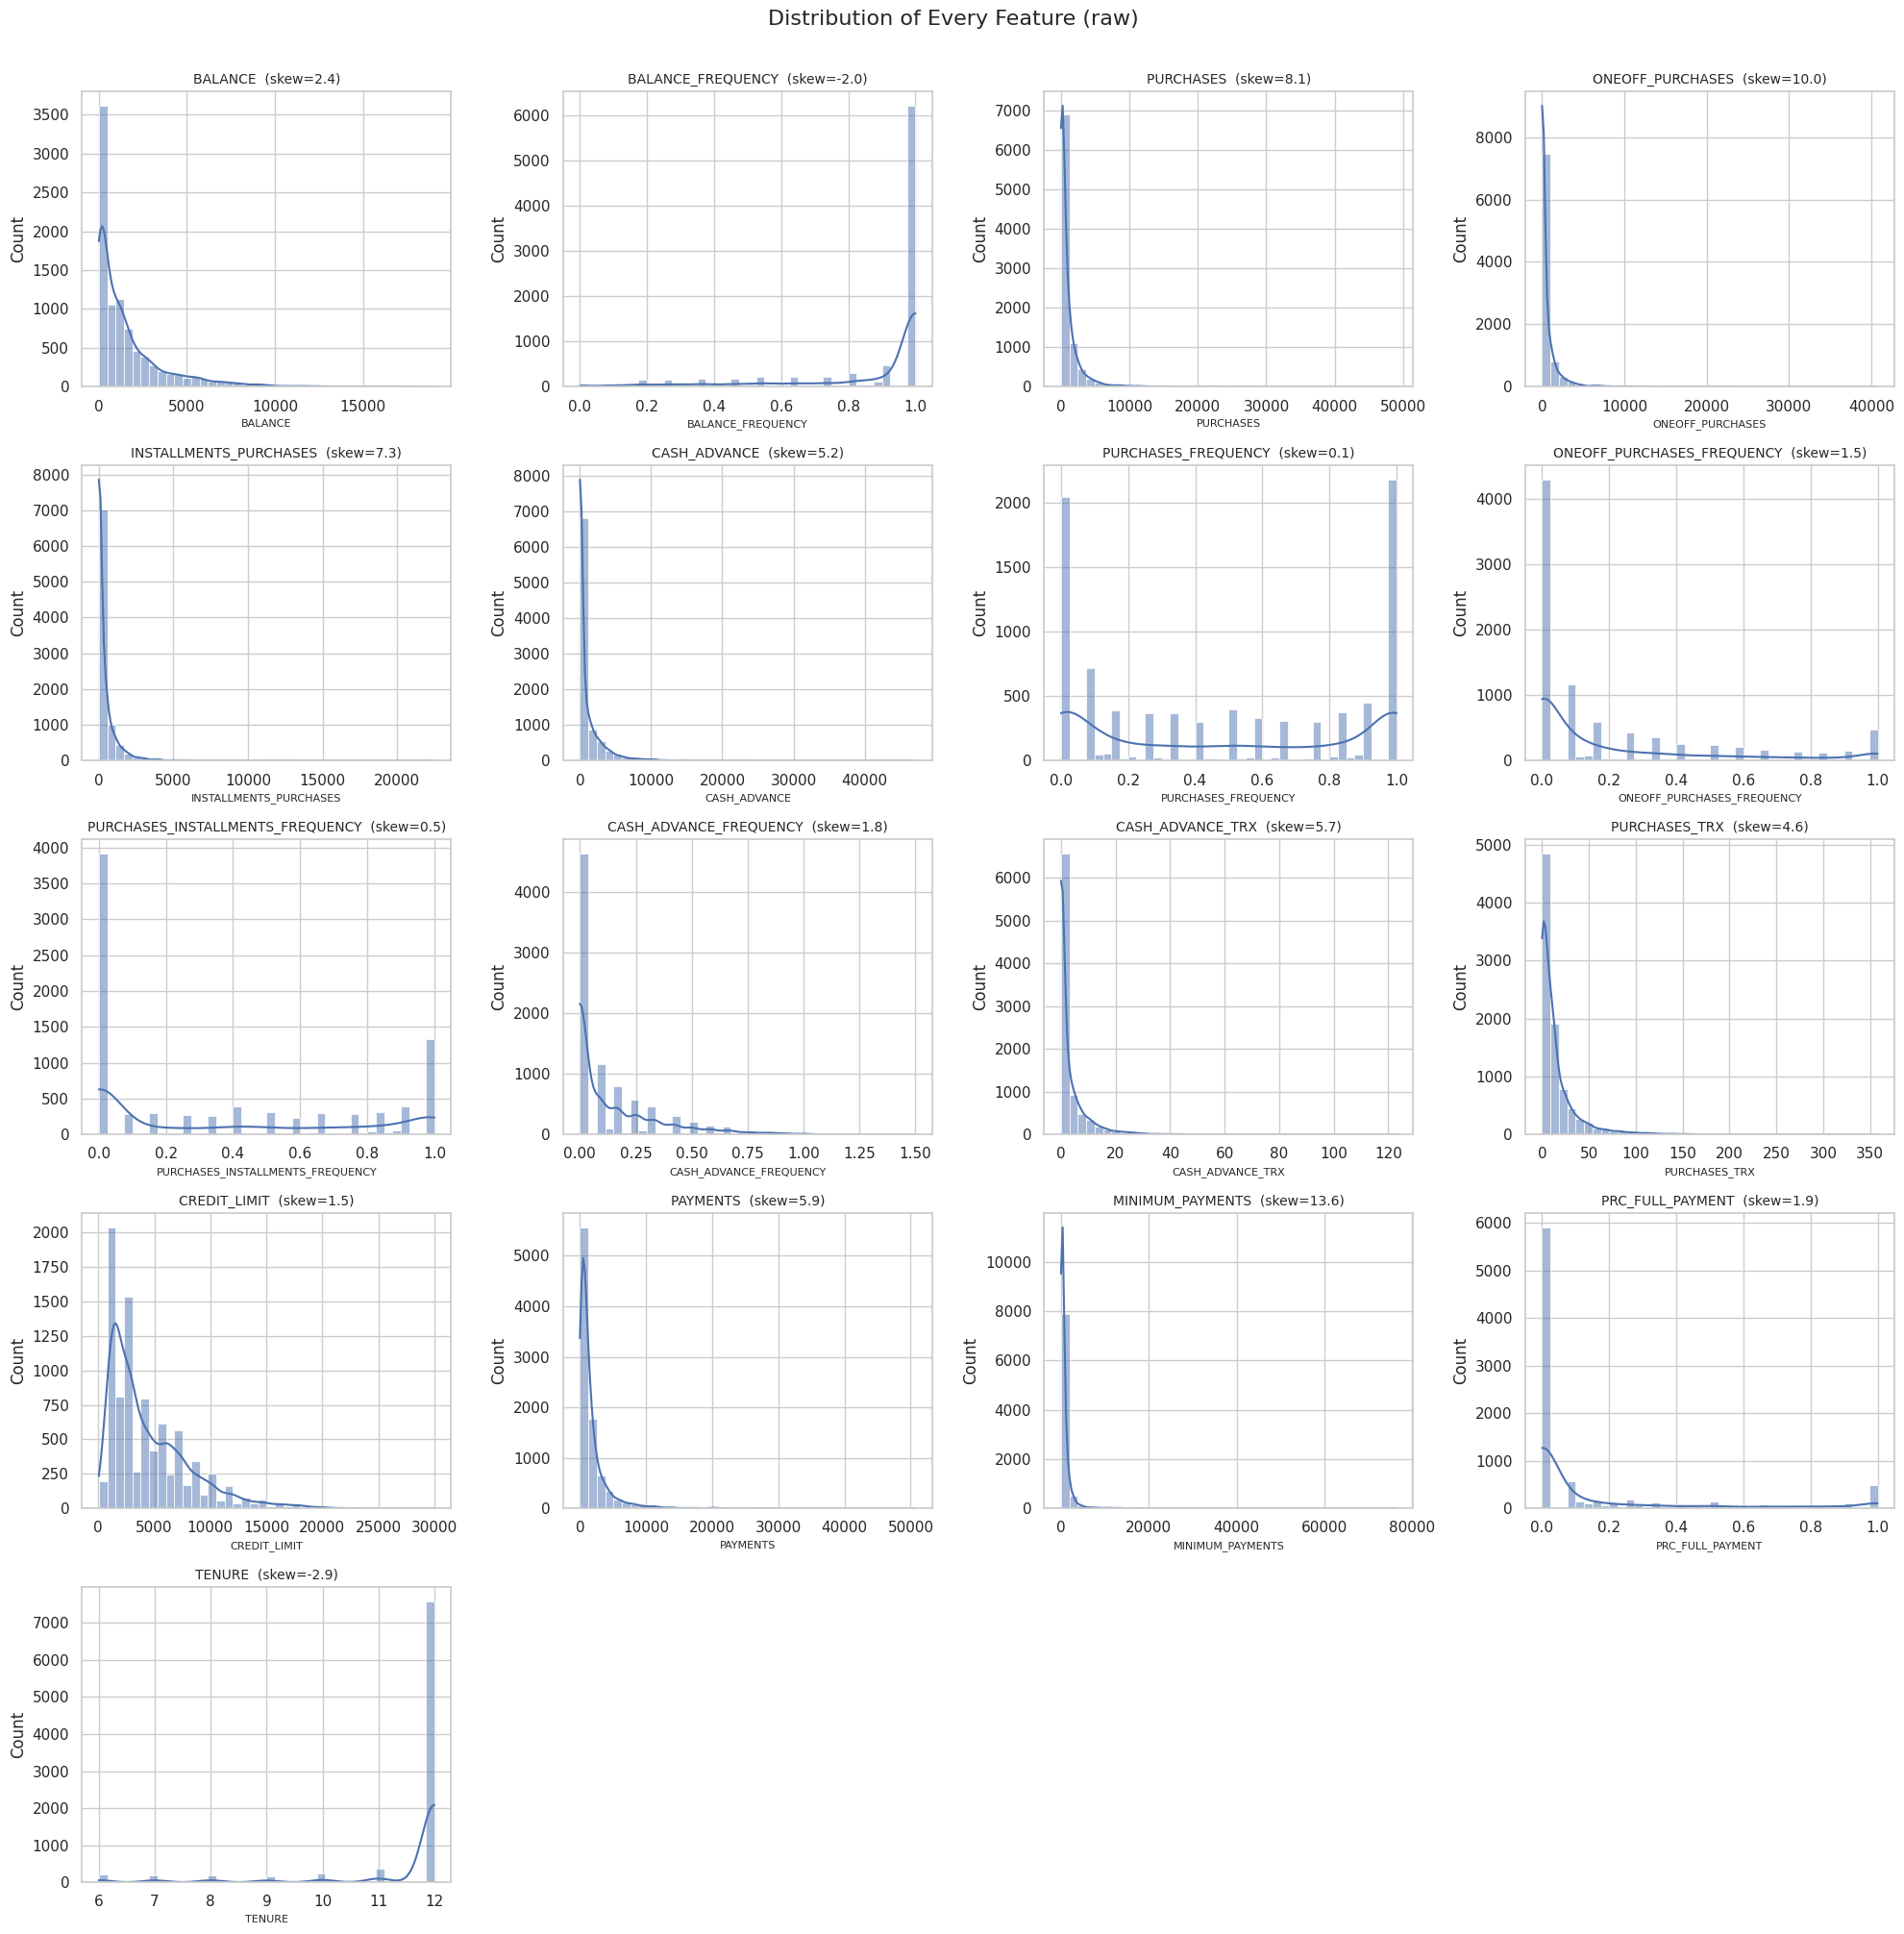

In [5]:
feature_cols = [c for c in df.columns if c != 'ID']

fig, axes = plt.subplots(5, 4, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(feature_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=axes[i], color='#4C72B0', bins=40)
    axes[i].set_title(f'{col}  (skew={df[col].skew():.1f})', fontsize=10)
    axes[i].set_xlabel(col, fontsize=8)
    axes[i].set_ylabel('Count')
for j in range(len(feature_cols), len(axes)):
    fig.delaxes(axes[j])
fig.suptitle('Distribution of Every Feature (raw)', fontsize=16, y=1.005)
plt.tight_layout()
plt.savefig('../models/clu_feature_distributions.png', bbox_inches='tight')
plt.show()

**Observation:** Almost every monetary feature (`PURCHASES`, `ONEOFF_PURCHASES`, `CASH_ADVANCE`, `PAYMENTS`, `MINIMUM_PAYMENTS`) is **extremely right-skewed** (skew 5–14) with a large spike at **zero**: most customers never take a cash advance and many never make one-off purchases. The frequency features are **bimodal** (piled up at 0 and at 1) — customers tend to either always or never use a given feature. `TENURE` and `BALANCE_FREQUENCY` are skewed the other way (most at the maximum). Skews this strong would let a few extreme customers dominate any Euclidean-distance clustering, which is why B3 applies a log transform.

### A2.2 Box plots — outlier view on the monetary features

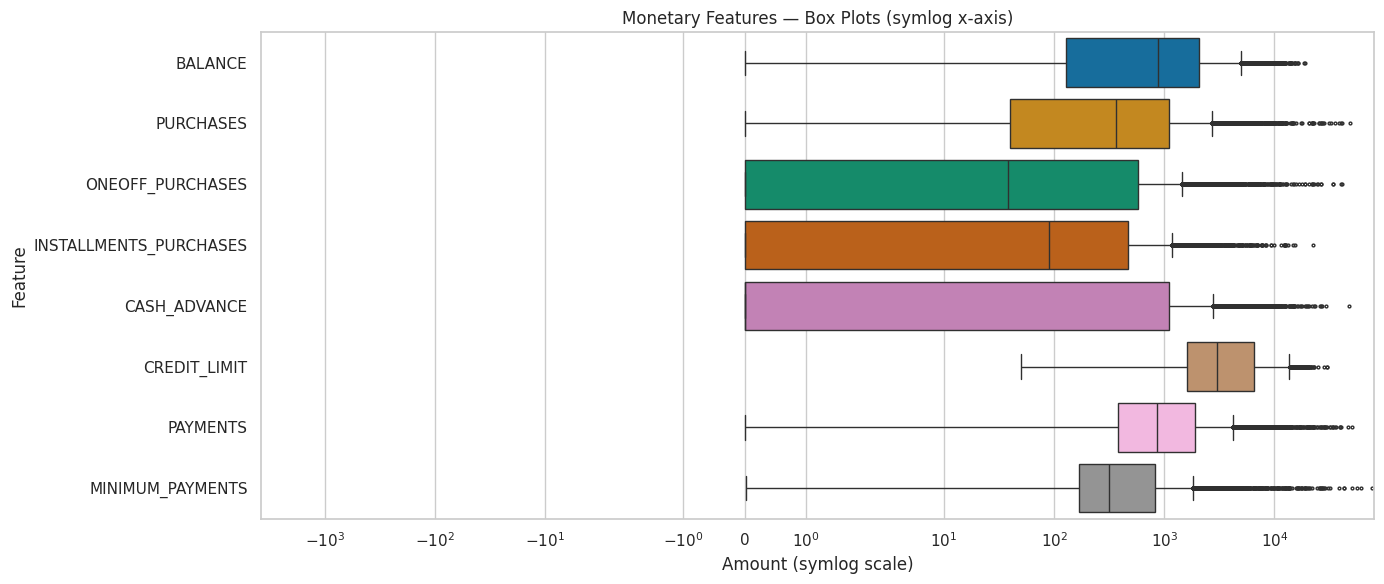

,Feature,IQR upper fence,Outliers,Percent,Max
0,BALANCE,"4,943",695,7.8%,"19,043"
1,PURCHASES,"2,716",808,9.0%,"49,040"
2,ONEOFF_PURCHASES,"1,444",1013,11.3%,"40,761"
3,INSTALLMENTS_PURCHASES,"1,172",867,9.7%,"22,500"
4,CASH_ADVANCE,"2,785",1030,11.5%,"47,137"
5,CREDIT_LIMIT,"13,850",248,2.8%,"30,000"
6,PAYMENTS,"4,178",808,9.0%,"50,721"
7,MINIMUM_PAYMENTS,"1,810",841,9.4%,"76,406"


In [6]:
money_cols = ['BALANCE', 'PURCHASES', 'ONEOFF_PURCHASES', 'INSTALLMENTS_PURCHASES', 'CASH_ADVANCE',
              'CREDIT_LIMIT', 'PAYMENTS', 'MINIMUM_PAYMENTS']

outlier_rows = []
for col in money_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    upper = q3 + 1.5 * (q3 - q1)
    outlier_rows.append({'Feature': col, 'IQR upper fence': upper, 'Outliers': int((df[col] > upper).sum()),
                         'Percent': (df[col] > upper).mean() * 100, 'Max': df[col].max()})
outlier_df = pd.DataFrame(outlier_rows)

fig, ax = plt.subplots(figsize=(14, 6))
sns.boxplot(data=df[money_cols], orient='h', ax=ax, palette='colorblind', fliersize=2)
ax.set_xscale('symlog')
ax.set_title('Monetary Features — Box Plots (symlog x-axis)')
ax.set_xlabel('Amount (symlog scale)')
ax.set_ylabel('Feature')
plt.tight_layout()
plt.savefig('../models/clu_boxplots.png', bbox_inches='tight')
plt.show()

outlier_df.style.format({'IQR upper fence': '{:,.0f}', 'Percent': '{:.1f}%', 'Max': '{:,.0f}'})

**Observation:** By the IQR rule, **8–11%** of customers are outliers on each monetary feature (e.g. 1,030 on `CASH_ADVANCE`, max 47,137 vs. a fence of 2,785). These are not data errors — they are genuine high spenders and heavy borrowers, and from a risk perspective they are some of the most important customers to segment correctly. They are therefore **kept**, and their influence on the distance metric is reduced with `log1p` rather than by deleting or capping them.

### A2.3 Correlation heatmap

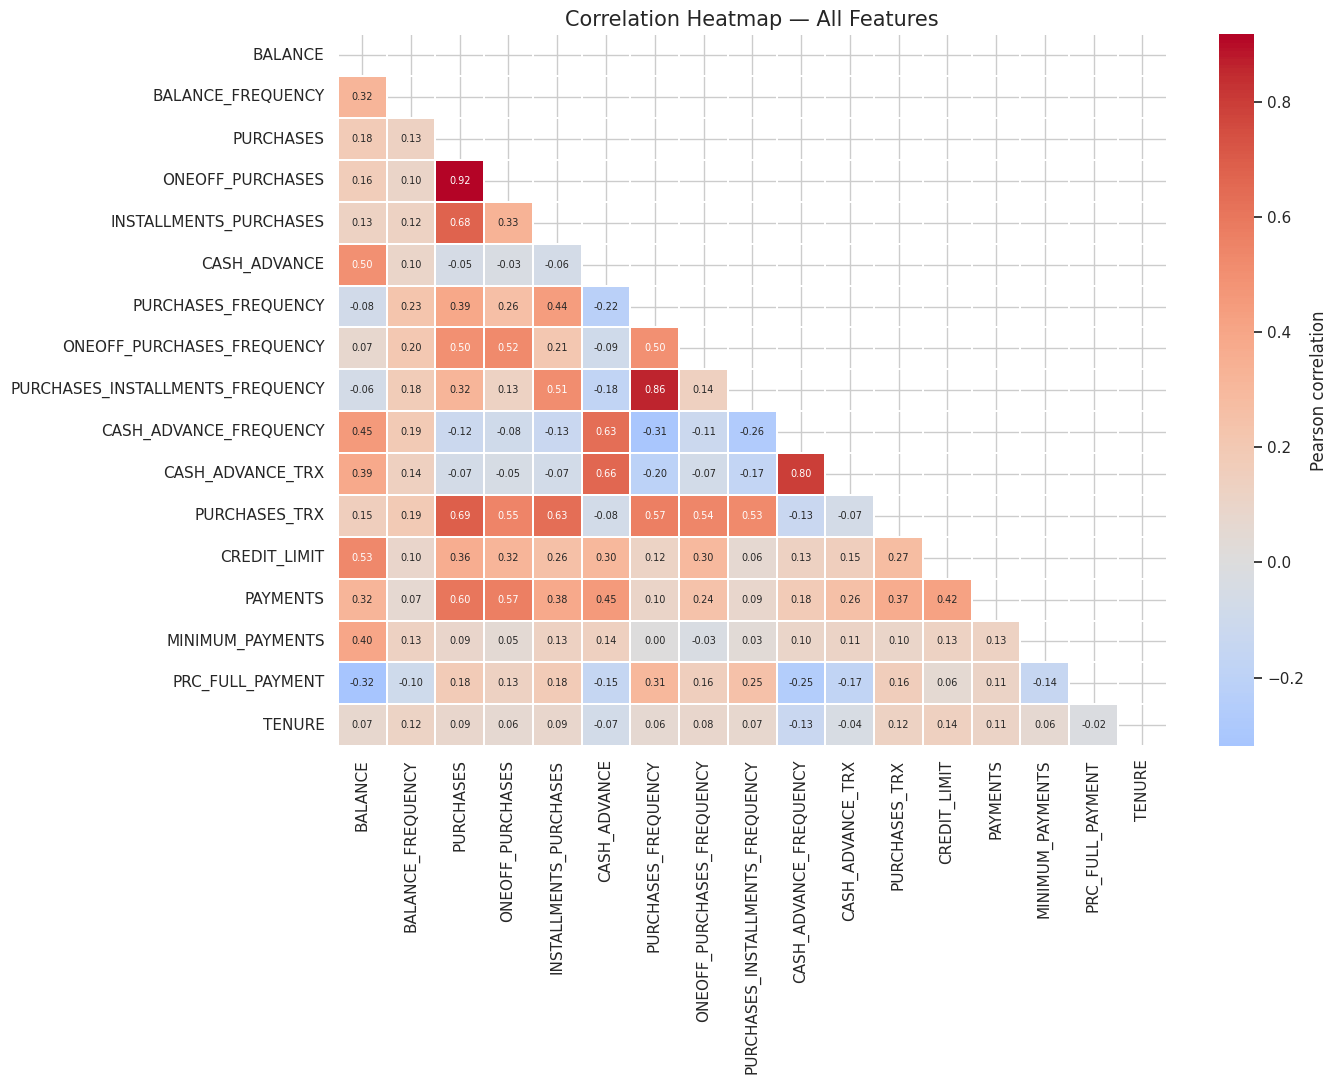

Most strongly correlated feature pairs:
PURCHASES               ONEOFF_PURCHASES                    0.917
PURCHASES_FREQUENCY     PURCHASES_INSTALLMENTS_FREQUENCY    0.863
CASH_ADVANCE_FREQUENCY  CASH_ADVANCE_TRX                    0.800
PURCHASES               PURCHASES_TRX                       0.690
                        INSTALLMENTS_PURCHASES              0.680
CASH_ADVANCE            CASH_ADVANCE_TRX                    0.656
                        CASH_ADVANCE_FREQUENCY              0.629
INSTALLMENTS_PURCHASES  PURCHASES_TRX                       0.628
dtype: float64


In [7]:
plt.figure(figsize=(14, 11))
corr = df[feature_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, annot=True, fmt='.2f', annot_kws={'size': 7},
            linewidths=0.3, cbar_kws={'label': 'Pearson correlation'})
plt.title('Correlation Heatmap — All Features', fontsize=15)
plt.tight_layout()
plt.savefig('../models/clu_correlation_heatmap.png', bbox_inches='tight')
plt.show()

pairs = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().sort_values(key=abs, ascending=False)
print('Most strongly correlated feature pairs:')
print(pairs.head(8).round(3))

**Observation:** Several features measure almost the same behaviour: `PURCHASES` vs. `ONEOFF_PURCHASES` (**r = 0.92**), `PURCHASES_FREQUENCY` vs. `PURCHASES_INSTALLMENTS_FREQUENCY` (0.86) and `CASH_ADVANCE_FREQUENCY` vs. `CASH_ADVANCE_TRX` (0.80). Left as they are, K-Means would count purchasing behaviour and cash-advance behaviour several times over in its distance calculation. This redundancy is removed with PCA in B3. Purchase-related and cash-advance-related features are only weakly correlated with each other, which already hints that "spenders" and "cash-advance users" will form different groups.

### A2.4 Feature relationships (scatter plots)

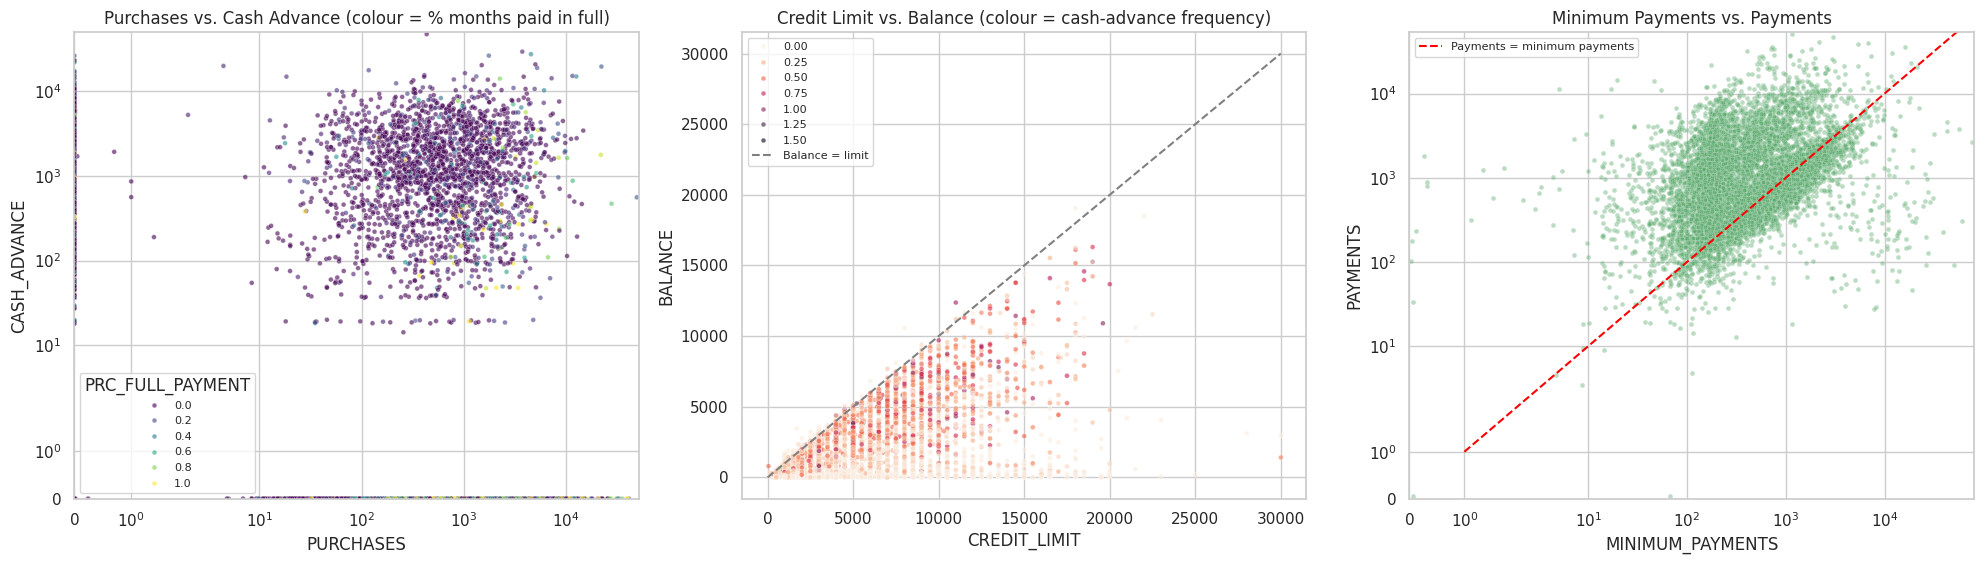

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

sns.scatterplot(data=df, x='PURCHASES', y='CASH_ADVANCE', hue='PRC_FULL_PAYMENT', palette='viridis',
                s=12, alpha=0.6, ax=axes[0])
axes[0].set_xscale('symlog'); axes[0].set_yscale('symlog')
axes[0].set_xlim(left=0); axes[0].set_ylim(bottom=0)
axes[0].set_title('Purchases vs. Cash Advance (colour = % months paid in full)')
axes[0].legend(title='PRC_FULL_PAYMENT', fontsize=8)

sns.scatterplot(data=df, x='CREDIT_LIMIT', y='BALANCE', hue='CASH_ADVANCE_FREQUENCY', palette='rocket_r',
                s=12, alpha=0.6, ax=axes[1])
axes[1].plot([0, 30000], [0, 30000], ls='--', color='grey', label='Balance = limit')
axes[1].set_title('Credit Limit vs. Balance (colour = cash-advance frequency)')
axes[1].legend(fontsize=8)

sns.scatterplot(data=df, x='MINIMUM_PAYMENTS', y='PAYMENTS', s=12, alpha=0.4, color='#55A868', ax=axes[2])
axes[2].set_xscale('symlog'); axes[2].set_yscale('symlog')
axes[2].set_xlim(left=0); axes[2].set_ylim(bottom=0)
lim = [1, 80000]
axes[2].plot(lim, lim, ls='--', color='red', label='Payments = minimum payments')
axes[2].set_title('Minimum Payments vs. Payments')
axes[2].legend(fontsize=8)

plt.tight_layout()
plt.savefig('../models/clu_scatter_relationships.png', bbox_inches='tight')
plt.show()

**Observation:** (1) Purchases and cash advances form two arms: many customers do one **or** the other, and customers who pay their balance in full (yellow) sit mostly on the purchases arm with little cash advance. (2) A large group of customers sits close to the **balance = limit** line, and they tend to be heavy cash-advance users (darker colour), which makes utilisation a promising risk variable. (3) Many customers lie on or below the **payments = minimum payments** line: they pay only the minimum (or less) and revolve their balance. These three patterns directly motivate the engineered features `CREDIT_UTILIZATION` and `PAYMENT_TO_MIN_RATIO`.

## Section B — Preprocessing & Feature Engineering

### B1 — Data cleaning

| Issue | Rows | Treatment | Justification |
|---|---|---|---|
| `ID` column | all | dropped | identifier, not behaviour |
| `CREDIT_LIMIT` missing | 1 | row dropped | a single row (0.01%); a credit limit cannot be inferred reliably and is needed for the utilisation feature |
| `MINIMUM_PAYMENTS` missing **and** `PAYMENTS == 0` | see A1 | set to **0** | structural missingness: a customer who paid nothing made no minimum payment either |
| `MINIMUM_PAYMENTS` missing, `PAYMENTS > 0` | remainder | **median** of the column | the column is extremely right-skewed, so the median is a far more representative fill value than the mean |
| `CASH_ADVANCE_FREQUENCY > 1` | 8 | clipped to 1 | invalid by definition (fraction of months) |
| Extreme monetary values | many | **kept**, then `log1p`-transformed (B3) | they are real big spenders/borrowers — exactly the customers a risk segmentation must see; capping would hide them |

Duplicates were checked in A1 (none).

In [9]:
df_clean = df.drop(columns=['ID']).copy()

n_before = len(df_clean)
df_clean = df_clean.dropna(subset=['CREDIT_LIMIT'])
print(f'Dropped {n_before - len(df_clean)} row with missing CREDIT_LIMIT -> {len(df_clean)} rows')

structural = df_clean['MINIMUM_PAYMENTS'].isna() & (df_clean['PAYMENTS'] == 0)
df_clean.loc[structural, 'MINIMUM_PAYMENTS'] = 0.0
MIN_PAYMENTS_MEDIAN = df_clean['MINIMUM_PAYMENTS'].median()
remaining = df_clean['MINIMUM_PAYMENTS'].isna()
df_clean.loc[remaining, 'MINIMUM_PAYMENTS'] = MIN_PAYMENTS_MEDIAN
print(f'MINIMUM_PAYMENTS: {structural.sum()} structural gaps set to 0, '
      f'{remaining.sum()} remaining gaps filled with median = {MIN_PAYMENTS_MEDIAN:.2f}')

n_invalid = (df_clean['CASH_ADVANCE_FREQUENCY'] > 1).sum()
df_clean['CASH_ADVANCE_FREQUENCY'] = df_clean['CASH_ADVANCE_FREQUENCY'].clip(upper=1.0)
print(f'Clipped {n_invalid} invalid CASH_ADVANCE_FREQUENCY values to 1.0')

print(f'\nMissing values remaining: {df_clean.isna().sum().sum()}')

Dropped 1 row with missing CREDIT_LIMIT -> 8949 rows
MINIMUM_PAYMENTS: 240 structural gaps set to 0, 73 remaining gaps filled with median = 294.59
Clipped 8 invalid CASH_ADVANCE_FREQUENCY values to 1.0

Missing values remaining: 0


### B2 — Feature engineering

Four features are engineered because the raw columns describe *amounts*, while credit risk is about *ratios* and *rates*:

1. **`CREDIT_UTILIZATION` = BALANCE / CREDIT_LIMIT** — the single most widely used revolving-credit risk indicator (credit bureaus treat utilisation above ~30% as a warning sign). Two customers with the same balance but different limits carry very different risk; neither raw column shows this.
2. **`PAYMENT_TO_MIN_RATIO` = PAYMENTS / (MINIMUM_PAYMENTS + 1)** — a value near 1 means the customer only ever pays the minimum (a classic revolver who accumulates interest); large values mean they repay well above the minimum. This separates *transactors* from *revolvers*, which no single raw column does.
3. **`MONTHLY_PURCHASES` = PURCHASES / TENURE** and 4. **`MONTHLY_CASH_ADVANCE` = CASH_ADVANCE / TENURE** — totals are not comparable between a 6-month and a 12-month customer; dividing by tenure puts everyone on the same per-month scale.

We expect these to help the clustering because distance-based algorithms can only group customers on what the feature space makes explicit.

In [10]:
def engineer_features(frame):
    """Add the four engineered risk features (used identically by the notebook and the web app)."""
    out = frame.copy()
    out['CREDIT_UTILIZATION'] = out['BALANCE'] / out['CREDIT_LIMIT']
    out['PAYMENT_TO_MIN_RATIO'] = out['PAYMENTS'] / (out['MINIMUM_PAYMENTS'] + 1)
    out['MONTHLY_PURCHASES'] = out['PURCHASES'] / out['TENURE']
    out['MONTHLY_CASH_ADVANCE'] = out['CASH_ADVANCE'] / out['TENURE']
    return out


df_feat = engineer_features(df_clean)
eng_cols = ['CREDIT_UTILIZATION', 'PAYMENT_TO_MIN_RATIO', 'MONTHLY_PURCHASES', 'MONTHLY_CASH_ADVANCE']
print(df_feat[eng_cols].describe().round(3))
print(f'\nCustomers with utilisation above 30%: {(df_feat["CREDIT_UTILIZATION"] > 0.3).mean():.1%}')
print(f'Customers over their limit (utilisation > 100%): {(df_feat["CREDIT_UTILIZATION"] > 1).sum()}')

       CREDIT_UTILIZATION  PAYMENT_TO_MIN_RATIO  MONTHLY_PURCHASES  \
count            8949.000              8949.000           8949.000   
mean                0.389                 6.393             86.185   
std                 0.390                31.999            180.517   
min                 0.000                 0.000              0.000   
25%                 0.042                 0.912              3.422   
50%                 0.303                 2.017             31.940   
75%                 0.718                 6.015             97.230   
max                15.910              1863.850           4086.631   

       MONTHLY_CASH_ADVANCE  
count              8949.000  
mean                 88.984  
std                 193.146  
min                   0.000  
25%                   0.000  
50%                   0.000  
75%                  99.108  
max                3928.101  

Customers with utilisation above 30%: 50.2%
Customers over their limit (utilisation > 100%): 227


### B3 — Skew correction, scaling and dimensionality reduction

- **Log transform:** K-Means and Ward linkage minimise squared Euclidean distances, so a feature with a skew of 10+ would let a handful of extreme customers dominate the centroids. Every non-negative feature with skew > 1 is transformed with `log1p` (which also handles the many exact zeros).
- **Scaling:** `StandardScaler` puts every feature on mean 0 / std 1 so that no feature dominates the distance just because of its units (rupees vs. fractions).
- **No train/test split:** clustering has no target, so there is nothing to leak; the scaler and PCA are fitted on the full cleaned dataset, which is the population being segmented. (For the regression/classification tracks the scaler is fitted on the training split only.)
- **PCA:** many features are strongly correlated (A2.3), which would count the same behaviour several times in the distance. PCA keeps the components explaining **90%** of the variance and removes that redundancy before clustering.

In [11]:
skewed_cols = [c for c in df_feat.columns if df_feat[c].skew() > 1 and df_feat[c].min() >= 0]
df_model = df_feat.copy()
df_model[skewed_cols] = np.log1p(df_model[skewed_cols])

skew_table = pd.DataFrame({'skew before': df_feat[skewed_cols].skew(), 'skew after log1p': df_model[skewed_cols].skew()})
print(f'{len(skewed_cols)} of {df_feat.shape[1]} features log1p-transformed:')
print(skew_table.round(2))

FEATURE_ORDER = df_model.columns.tolist()
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_model[FEATURE_ORDER])
print(f'\nScaled feature matrix: {X_scaled.shape}')

17 of 21 features log1p-transformed:
                            skew before  skew after log1p
BALANCE                            2.39             -0.86
PURCHASES                          8.14             -0.76
ONEOFF_PURCHASES                  10.04              0.19
INSTALLMENTS_PURCHASES             7.30             -0.03
CASH_ADVANCE                       5.17              0.26
ONEOFF_PURCHASES_FREQUENCY         1.54              1.29
CASH_ADVANCE_FREQUENCY             1.79              1.44
CASH_ADVANCE_TRX                   5.72              0.94
PURCHASES_TRX                      4.63              0.03
CREDIT_LIMIT                       1.52             -0.10
PAYMENTS                           5.91             -1.78
MINIMUM_PAYMENTS                  13.82             -1.18
PRC_FULL_PAYMENT                   1.94              1.75
CREDIT_UTILIZATION                 7.42              0.39
PAYMENT_TO_MIN_RATIO              36.89              1.03
MONTHLY_PURCHASES                  

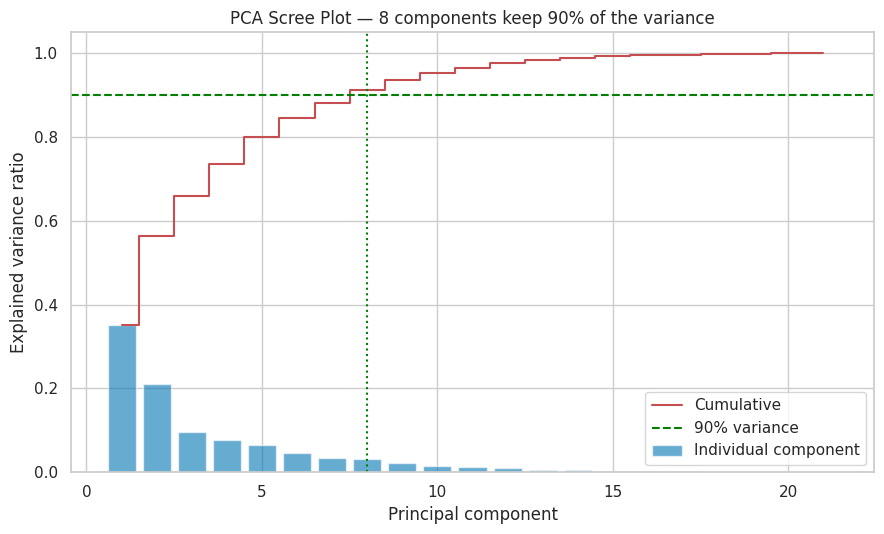

21 scaled features -> 8 PCA components (91.3% variance). Clustering input: (8949, 8)


In [12]:
pca_full = PCA(random_state=RANDOM_STATE).fit(X_scaled)
cum_var = np.cumsum(pca_full.explained_variance_ratio_)
N_COMPONENTS = int(np.argmax(cum_var >= 0.90) + 1)

plt.figure(figsize=(9, 5.5))
plt.bar(range(1, len(cum_var) + 1), pca_full.explained_variance_ratio_, alpha=0.6, label='Individual component')
plt.step(range(1, len(cum_var) + 1), cum_var, where='mid', color='#C44E52', label='Cumulative')
plt.axhline(0.90, color='green', linestyle='--', label='90% variance')
plt.axvline(N_COMPONENTS, color='green', linestyle=':')
plt.xlabel('Principal component')
plt.ylabel('Explained variance ratio')
plt.title(f'PCA Scree Plot — {N_COMPONENTS} components keep 90% of the variance')
plt.legend()
plt.tight_layout()
plt.savefig('../models/clu_pca_scree.png', bbox_inches='tight')
plt.show()

pca = PCA(n_components=N_COMPONENTS, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)
print(f'{X_scaled.shape[1]} scaled features -> {N_COMPONENTS} PCA components ({cum_var[N_COMPONENTS - 1]:.1%} variance). '
      f'Clustering input: {X_pca.shape}')

**Observation:** `log1p` brings 17 of the 21 features from skews of up to 37 down to roughly −1.8 … +1.8 (e.g. `MINIMUM_PAYMENTS` 13.8 → −1.2, `PAYMENT_TO_MIN_RATIO` 36.9 → 1.0). After scaling, **8 principal components keep 91.3%** of the variance of the 21 features, so the clustering works in 8 decorrelated dimensions instead of 21 partly redundant ones. That removes double-counting and makes K-Means faster and more stable.

## Section C — K-Means Clustering

### C1 — Elbow curve (inertia vs. k) and silhouette vs. k

K-Means is run for k = 2 … 10 (`n_init=10`, `random_state=42`). Inertia (within-cluster sum of squares) always falls as k grows, so the **elbow** — where adding a cluster stops paying off — is located with the *maximum-distance-to-chord* (Kneedle) rule rather than by eye. All three required metrics are also tracked for every k.

Elbow (Kneedle) located at k = 5


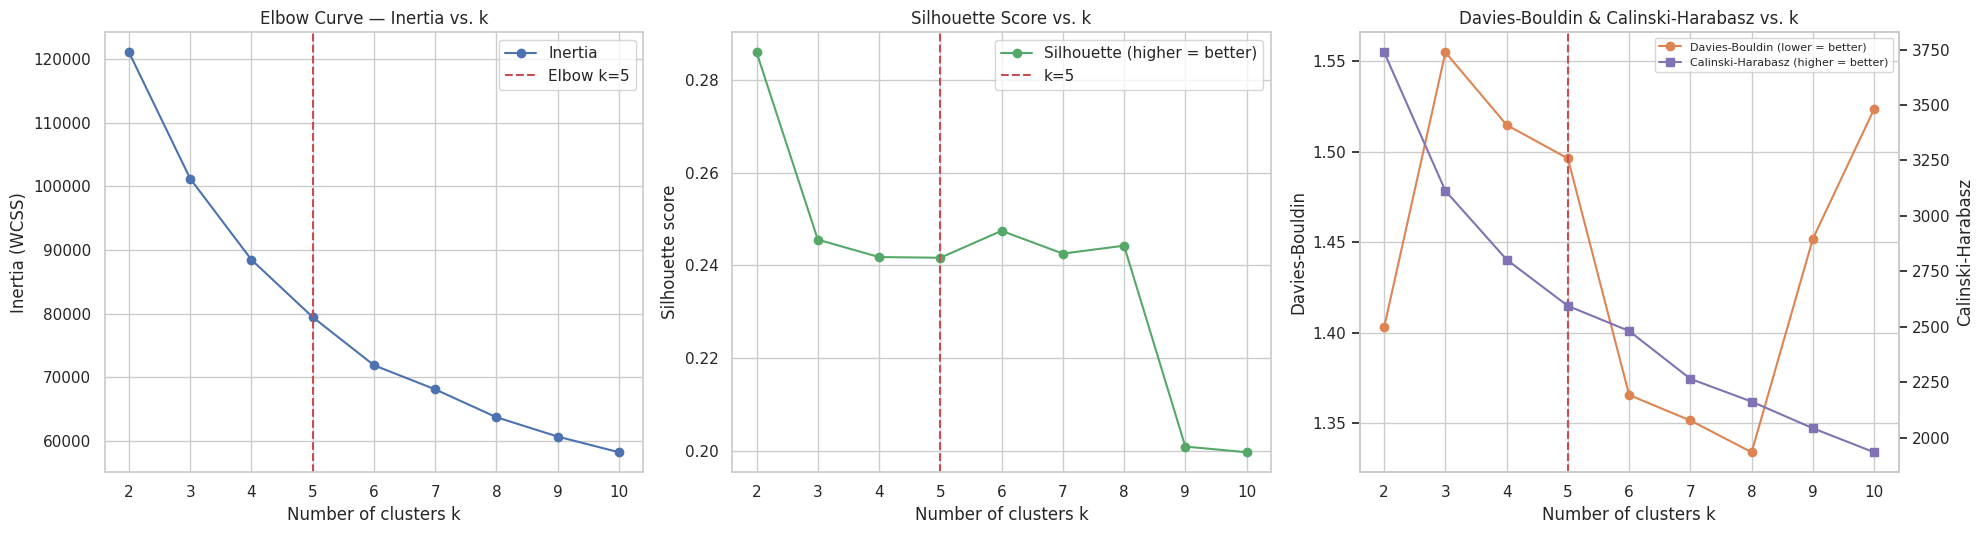

,k,Inertia,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster
0,2,"121,056",0.2859,1.4030,"3,737.7",3437
1,3,"101,198",0.2456,1.5549,"3,113.1",2821
2,4,"88,464",0.2418,1.5148,"2,803.0",1598
3,5,"79,448",0.2417,1.4962,"2,594.3",1252
4,6,"71,895",0.2475,1.3654,"2,481.1",975
5,7,"68,104",0.2426,1.3514,"2,265.5",742
6,8,"63,724",0.2443,1.3338,"2,162.9",254
7,9,"60,690",0.2010,1.4519,"2,042.7",252
8,10,"58,225",0.1998,1.5236,"1,934.5",251


In [13]:
def find_elbow(ks, values):
    """Kneedle-style elbow: the point farthest from the straight line joining the first and last points."""
    ks, values = np.asarray(ks, float), np.asarray(values, float)
    x = (ks - ks.min()) / (ks.max() - ks.min())
    y = (values - values.min()) / (values.max() - values.min())
    distances = np.abs((y[-1] - y[0]) * x - (x[-1] - x[0]) * y + x[-1] * y[0] - y[-1] * x[0]) / np.hypot(y[-1] - y[0], x[-1] - x[0])
    return int(ks[np.argmax(distances)])


k_range = range(2, 11)
k_rows = []
for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_pca)
    k_rows.append({'k': k, 'Inertia': km.inertia_,
                   'Silhouette': silhouette_score(X_pca, km.labels_),
                   'Davies-Bouldin': davies_bouldin_score(X_pca, km.labels_),
                   'Calinski-Harabasz': calinski_harabasz_score(X_pca, km.labels_),
                   'Smallest cluster': np.bincount(km.labels_).min()})
k_df = pd.DataFrame(k_rows)
elbow_k = find_elbow(k_df['k'], k_df['Inertia'])
print(f'Elbow (Kneedle) located at k = {elbow_k}')

fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
axes[0].plot(k_df['k'], k_df['Inertia'], marker='o', color='#4C72B0', label='Inertia')
axes[0].axvline(elbow_k, color='#C44E52', linestyle='--', label=f'Elbow k={elbow_k}')
axes[0].set_title('Elbow Curve — Inertia vs. k')
axes[0].set_xlabel('Number of clusters k'); axes[0].set_ylabel('Inertia (WCSS)'); axes[0].legend()

axes[1].plot(k_df['k'], k_df['Silhouette'], marker='o', color='#55A868', label='Silhouette (higher = better)')
axes[1].axvline(elbow_k, color='#C44E52', linestyle='--', label=f'k={elbow_k}')
axes[1].set_title('Silhouette Score vs. k')
axes[1].set_xlabel('Number of clusters k'); axes[1].set_ylabel('Silhouette score'); axes[1].legend()

axes[2].plot(k_df['k'], k_df['Davies-Bouldin'], marker='o', color='#DD8452', label='Davies-Bouldin (lower = better)')
ax2 = axes[2].twinx()
ax2.plot(k_df['k'], k_df['Calinski-Harabasz'], marker='s', color='#8172B3', label='Calinski-Harabasz (higher = better)')
axes[2].axvline(elbow_k, color='#C44E52', linestyle='--')
axes[2].set_title('Davies-Bouldin & Calinski-Harabasz vs. k')
axes[2].set_xlabel('Number of clusters k'); axes[2].set_ylabel('Davies-Bouldin'); ax2.set_ylabel('Calinski-Harabasz')
h1, l1 = axes[2].get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
axes[2].legend(h1 + h2, l1 + l2, loc='upper right', fontsize=8)
ax2.grid(False)

plt.tight_layout()
plt.savefig('../models/clu_elbow_silhouette.png', bbox_inches='tight')
plt.show()

k_df.style.format({'Inertia': '{:,.0f}', 'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}', 'Calinski-Harabasz': '{:,.1f}'}) \
    .highlight_max(subset=['Silhouette', 'Calinski-Harabasz'], color='#c7e9c0') \
    .highlight_min(subset=['Davies-Bouldin'], color='#c7e9c0')

**Observation — choosing k:** The elbow curve has no sharp corner; the Kneedle rule places it at **k = 5**, but inertia falls almost as smoothly through k = 4–6. The silhouette is highest at k = 2 (0.286), but two clusters only split "cash-advance users" from "everyone else", which is too coarse to act on. From k = 3 to 8 the silhouette is essentially **flat (0.24–0.25)**, and k = 4 and k = 5 are tied (0.2418 vs. 0.2417). **k = 4 is chosen** because:
1. the **dendrogram** (Section D1) shows a large gap before the 4-cluster level (merge-height jump 43.3) but almost none before 5 (jump 0.1), so the 5th cluster is not a natural split;
2. all four clusters are large (smallest = 1,598 customers, 18%), whereas from k = 8 a tiny cluster of ~250 customers appears;
3. the four clusters map onto four clearly different credit behaviours (Section G).

A silhouette of ~0.24 is moderate: customer behaviour forms a continuum, not perfectly separated blobs. That is typical for real behavioural data and is reported honestly rather than tuned away.

### C2 — Fit the final K-Means model

In [14]:
FINAL_K = 4

kmeans = KMeans(n_clusters=FINAL_K, n_init=10, random_state=RANDOM_STATE)
labels_km = kmeans.fit_predict(X_pca)

print(f'K-Means fitted with k = {FINAL_K}; {kmeans.n_iter_} iterations to converge; inertia = {kmeans.inertia_:,.0f}')
print('Cluster sizes:', dict(zip(*np.unique(labels_km, return_counts=True))))

K-Means fitted with k = 4; 15 iterations to converge; inertia = 88,464
Cluster sizes: {np.int32(0): np.int64(3204), np.int32(1): np.int64(1773), np.int32(2): np.int64(2374), np.int32(3): np.int64(1598)}


### C3 — Silhouette plot (per-customer cohesion/separation)

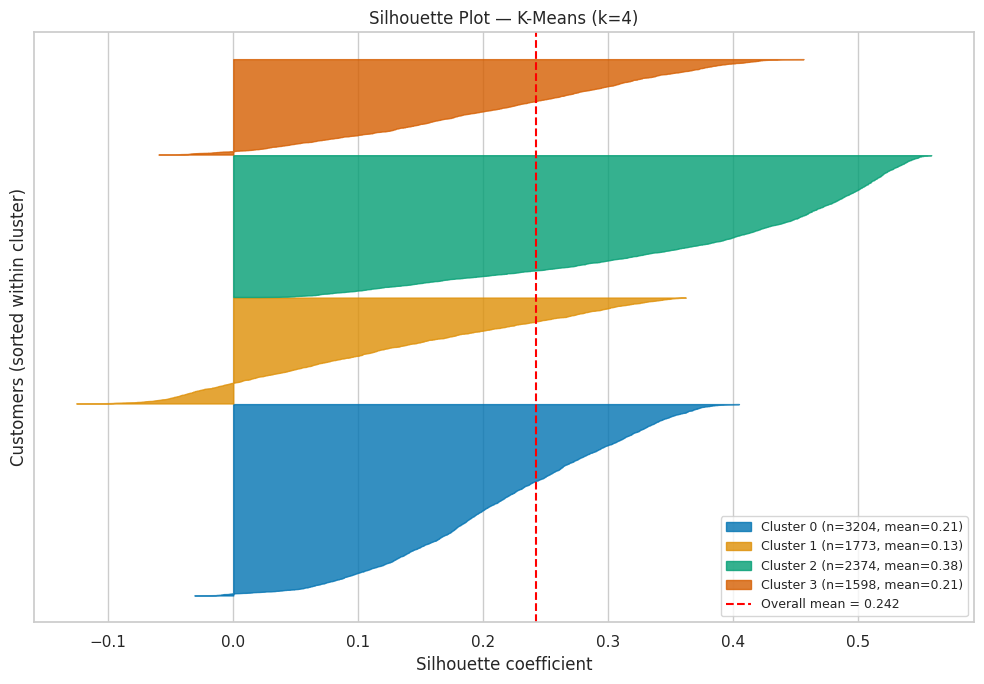

Customers with a negative silhouette (probably closer to another cluster): 4.9%


In [15]:
sil_values = silhouette_samples(X_pca, labels_km)
sil_avg = sil_values.mean()
colors = sns.color_palette('colorblind', FINAL_K)

fig, ax = plt.subplots(figsize=(10, 7))
y_lower = 10
for c in range(FINAL_K):
    vals = np.sort(sil_values[labels_km == c])
    ax.fill_betweenx(np.arange(y_lower, y_lower + len(vals)), 0, vals, color=colors[c], alpha=0.8,
                     label=f'Cluster {c} (n={len(vals)}, mean={vals.mean():.2f})')
    y_lower += len(vals) + 10
ax.axvline(sil_avg, color='red', linestyle='--', label=f'Overall mean = {sil_avg:.3f}')
ax.set_title(f'Silhouette Plot — K-Means (k={FINAL_K})')
ax.set_xlabel('Silhouette coefficient')
ax.set_ylabel('Customers (sorted within cluster)')
ax.set_yticks([])
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig('../models/clu_silhouette_plot_kmeans.png', bbox_inches='tight')
plt.show()

print(f'Customers with a negative silhouette (probably closer to another cluster): {(sil_values < 0).mean():.1%}')

**Observation:** Every cluster has a positive mean silhouette, and only **4.9%** of customers have a negative value (meaning they are closer to a neighbouring cluster than to their own). These are the customers on the boundaries between segments, for example a transactor who has started taking cash advances. The large, tall blades show that most customers sit firmly inside their segment.

## Section D — Agglomerative Hierarchical Clustering

### D1 — Dendrogram (Ward linkage)

The full merge tree is computed with SciPy on the same PCA input. With ~9,000 leaves the full tree is unreadable, so it is truncated to the last 30 merges; the horizontal line shows where the tree is cut to obtain 4 clusters. Long vertical gaps above the cut indicate well-separated groups.

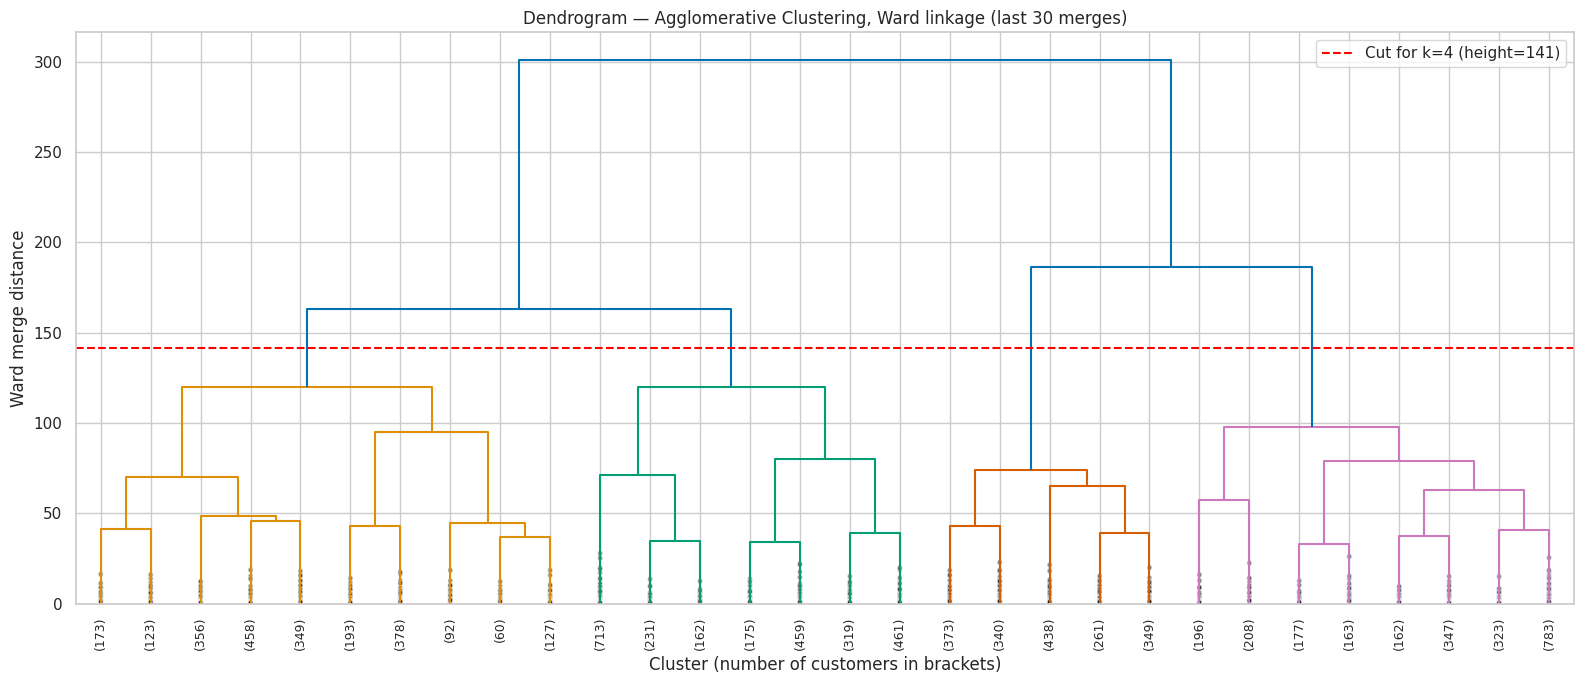

Merge heights of the last 8 merges (largest first): [301.1 186.5 163.1 119.9 119.8  97.5  94.8  79.8]
Jump in merge height when going from k to k-1 clusters:
  k=2: 114.6
  k=3: 23.4
  k=4: 43.3
  k=5: 0.1
  k=6: 22.3
  k=7: 2.7


In [16]:
Z_ward = linkage(X_pca, method='ward')

cut_height = (Z_ward[-FINAL_K, 2] + Z_ward[-FINAL_K + 1, 2]) / 2   # between the merges that give k and k-1 clusters

plt.figure(figsize=(16, 7))
dendrogram(Z_ward, truncate_mode='lastp', p=30, leaf_rotation=90, leaf_font_size=9,
           show_contracted=True, color_threshold=cut_height)
plt.axhline(cut_height, color='red', linestyle='--', label=f'Cut for k={FINAL_K} (height={cut_height:.0f})')
plt.title('Dendrogram — Agglomerative Clustering, Ward linkage (last 30 merges)')
plt.xlabel('Cluster (number of customers in brackets)')
plt.ylabel('Ward merge distance')
plt.legend()
plt.tight_layout()
plt.savefig('../models/clu_dendrogram_ward.png', bbox_inches='tight')
plt.show()

last_merges = Z_ward[-8:, 2][::-1]
print('Merge heights of the last 8 merges (largest first):', np.round(last_merges, 1))
print('Jump in merge height when going from k to k-1 clusters:')
for k in range(2, 8):
    print(f'  k={k}: {Z_ward[-k + 1, 2] - Z_ward[-k, 2]:.1f}')

**Observation:** The tree first splits into two large branches, cash-advance-driven customers (right) and purchase-driven customers (left), at a merge height of ~300. The cut at height 141 gives **4 clusters**, and the dendrogram supports this choice independently of K-Means: the 4-cluster level stays stable across a wide band of heights (≈120 to 163), whereas the 5-cluster level would exist only between 119.8 and 119.9.

### D2 — Comparing linkage strategies

All four linkage criteria are fitted with k = 4 on the same input. Besides the three metrics, the **cluster sizes** are reported, because a linkage can score deceptively well on Silhouette / Davies-Bouldin by isolating a few extreme outliers as their own "clusters" while lumping everyone else together.

In [17]:
linkage_rows, agglo_labels = [], {}
for method in ['ward', 'complete', 'average', 'single']:
    model = AgglomerativeClustering(n_clusters=FINAL_K, linkage=method)
    lab = model.fit_predict(X_pca)
    agglo_labels[method] = lab
    sizes = np.sort(np.bincount(lab))[::-1]
    linkage_rows.append({'Linkage': method,
                         'Silhouette': silhouette_score(X_pca, lab),
                         'Davies-Bouldin': davies_bouldin_score(X_pca, lab),
                         'Calinski-Harabasz': calinski_harabasz_score(X_pca, lab),
                         'Cluster sizes': ', '.join(map(str, sizes)),
                         'Largest cluster share': sizes[0] / len(lab)})
linkage_df = pd.DataFrame(linkage_rows)
linkage_df.style.format({'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}', 'Calinski-Harabasz': '{:,.1f}',
                         'Largest cluster share': '{:.1%}'})

,Linkage,Silhouette,Davies-Bouldin,Calinski-Harabasz,Cluster sizes,Largest cluster share
0,ward,0.1999,1.7153,"2,370.8","2520, 2359, 2309, 1761",28.2%
1,complete,0.1380,1.5324,702.2,"5829, 2858, 261, 1",65.1%
2,average,0.1919,1.0970,188.3,"8685, 250, 13, 1",97.0%
3,single,0.2834,0.6143,4.8,"8945, 2, 1, 1",100.0%


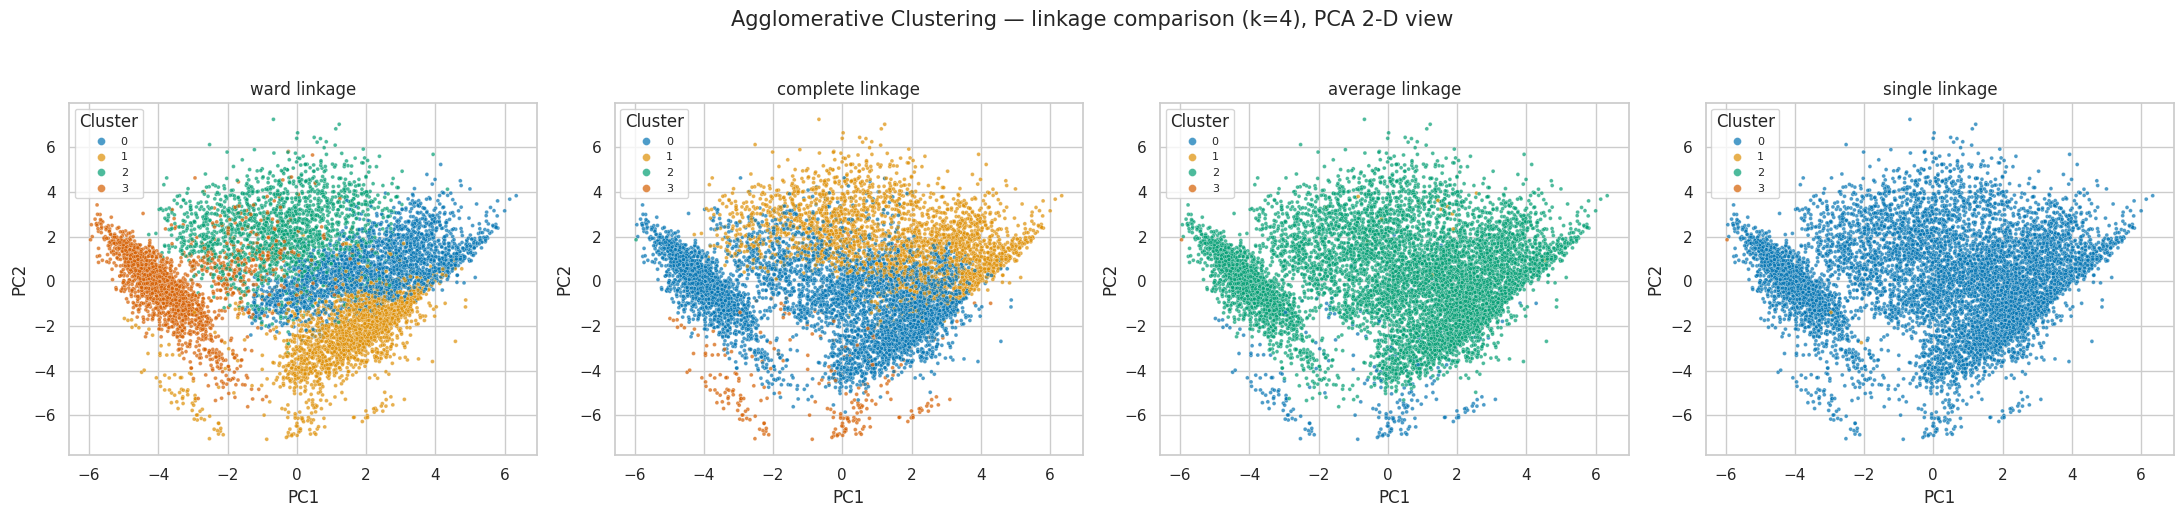

In [18]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5))
pca_2d_vis = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_scaled)
X_2d = pca_2d_vis.transform(X_scaled)
for ax, method in zip(axes, agglo_labels):
    sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=agglo_labels[method], palette='colorblind', s=8,
                    alpha=0.7, ax=ax, legend='full')
    ax.set_title(f'{method} linkage')
    ax.set_xlabel('PC1'); ax.set_ylabel('PC2')
    ax.legend(title='Cluster', fontsize=8, markerscale=2)
fig.suptitle('Agglomerative Clustering — linkage comparison (k=4), PCA 2-D view', fontsize=15, y=1.03)
plt.tight_layout()
plt.savefig('../models/clu_linkage_comparison.png', bbox_inches='tight')
plt.show()

**Observation:** This table shows why internal metrics must never be read without the cluster sizes. **Single linkage has the "best" Silhouette (0.283) and Davies-Bouldin (0.61)** of all methods, yet it puts **8,945 of 8,949 customers (100%) into one cluster** and makes three "clusters" of 1–2 outliers each (the chaining effect). Average linkage (97% in one cluster) and complete linkage (one singleton) fail in the same way, which their collapsed Calinski-Harabasz scores (5 – 702) reveal. **Ward linkage is the only one that produces four balanced, usable segments** (1,761–2,520 customers each). Ward merges the pair of clusters that least increases within-cluster variance, the same objective as K-Means, so it is the natural hierarchical partner and is used as the final Agglomerative model.

In [19]:
agglo = AgglomerativeClustering(n_clusters=FINAL_K, linkage='ward')
labels_ag = agglo.fit_predict(X_pca)
print('Final Agglomerative model: Ward linkage, k =', FINAL_K)
print('Cluster sizes:', dict(zip(*np.unique(labels_ag, return_counts=True))))

Final Agglomerative model: Ward linkage, k = 4
Cluster sizes: {np.int64(0): np.int64(2520), np.int64(1): np.int64(2309), np.int64(2): np.int64(1761), np.int64(3): np.int64(2359)}


## Section E — Evaluation Metrics (all algorithms)

| Metric | Range | Better | What it measures |
|---|---|---|---|
| Silhouette Score | −1 … 1 | higher | how much closer each point is to its own cluster than to the nearest other cluster |
| Davies-Bouldin Index | 0 … ∞ | lower | average similarity of each cluster with its most similar cluster (spread vs. separation) |
| Calinski-Harabasz Index | 0 … ∞ | higher | ratio of between-cluster to within-cluster dispersion |

In [20]:
def cluster_metrics(name, X, labels):
    return {'Algorithm': name,
            'k': len(np.unique(labels)),
            'Silhouette': silhouette_score(X, labels),
            'Davies-Bouldin': davies_bouldin_score(X, labels),
            'Calinski-Harabasz': calinski_harabasz_score(X, labels),
            'Smallest cluster': int(np.bincount(labels).min()),
            'Largest cluster': int(np.bincount(labels).max())}


metrics_df = pd.DataFrame([
    cluster_metrics('K-Means', X_pca, labels_km),
    cluster_metrics('Agglomerative (ward)', X_pca, labels_ag),
    cluster_metrics('Agglomerative (complete)', X_pca, agglo_labels['complete']),
    cluster_metrics('Agglomerative (average)', X_pca, agglo_labels['average']),
    cluster_metrics('Agglomerative (single)', X_pca, agglo_labels['single']),
])
metrics_df.style.format({'Silhouette': '{:.4f}', 'Davies-Bouldin': '{:.4f}', 'Calinski-Harabasz': '{:,.1f}'}) \
    .set_caption('Clustering comparison — same PCA input, k = 4')

,Algorithm,k,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster,Largest cluster
0,K-Means,4,0.2418,1.5148,"2,803.0",1598,3204
1,Agglomerative (ward),4,0.1999,1.7153,"2,370.8",1761,2520
2,Agglomerative (complete),4,0.1380,1.5324,702.2,1,5829
3,Agglomerative (average),4,0.1919,1.0970,188.3,1,8685
4,Agglomerative (single),4,0.2834,0.6143,4.8,1,8945


Agreement between K-Means and Ward (Adjusted Rand Index): 0.552  (1 = identical, 0 = chance)


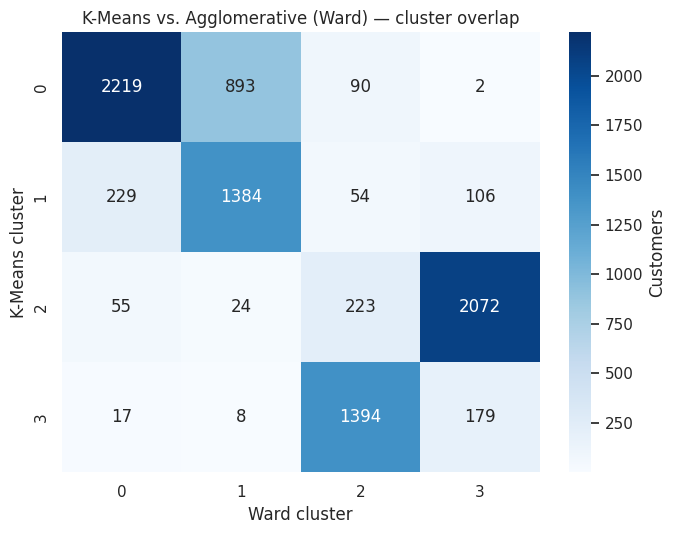

In [21]:
ari = adjusted_rand_score(labels_km, labels_ag)
print(f'Agreement between K-Means and Ward (Adjusted Rand Index): {ari:.3f}  (1 = identical, 0 = chance)')

ct = pd.crosstab(pd.Series(labels_km, name='K-Means cluster'), pd.Series(labels_ag, name='Ward cluster'))
plt.figure(figsize=(7, 5.5))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', cbar_kws={'label': 'Customers'})
plt.title('K-Means vs. Agglomerative (Ward) — cluster overlap')
plt.tight_layout()
plt.savefig('../models/clu_kmeans_vs_ward_crosstab.png', bbox_inches='tight')
plt.show()

**Observation:** **K-Means is the better of the two required algorithms on all three metrics**: Silhouette 0.242 vs. 0.200, Davies-Bouldin 1.515 vs. 1.715 (lower is better), Calinski-Harabasz 2,803 vs. 2,371. This is expected, because K-Means directly optimises the within-cluster variance that these metrics reward, while Ward builds greedily and can never undo an early merge. The two algorithms nevertheless broadly **agree (ARI = 0.55)**. The crosstab shows that the cash-advance segment is found almost identically by both; most disagreement is about where to draw the line between the purchase-heavy and low-activity customers. The degenerate single/average/complete linkages are listed only to document the linkage comparison.

## Section F — Cluster Visualisation

### F1 — PCA 2-D scatter for every algorithm

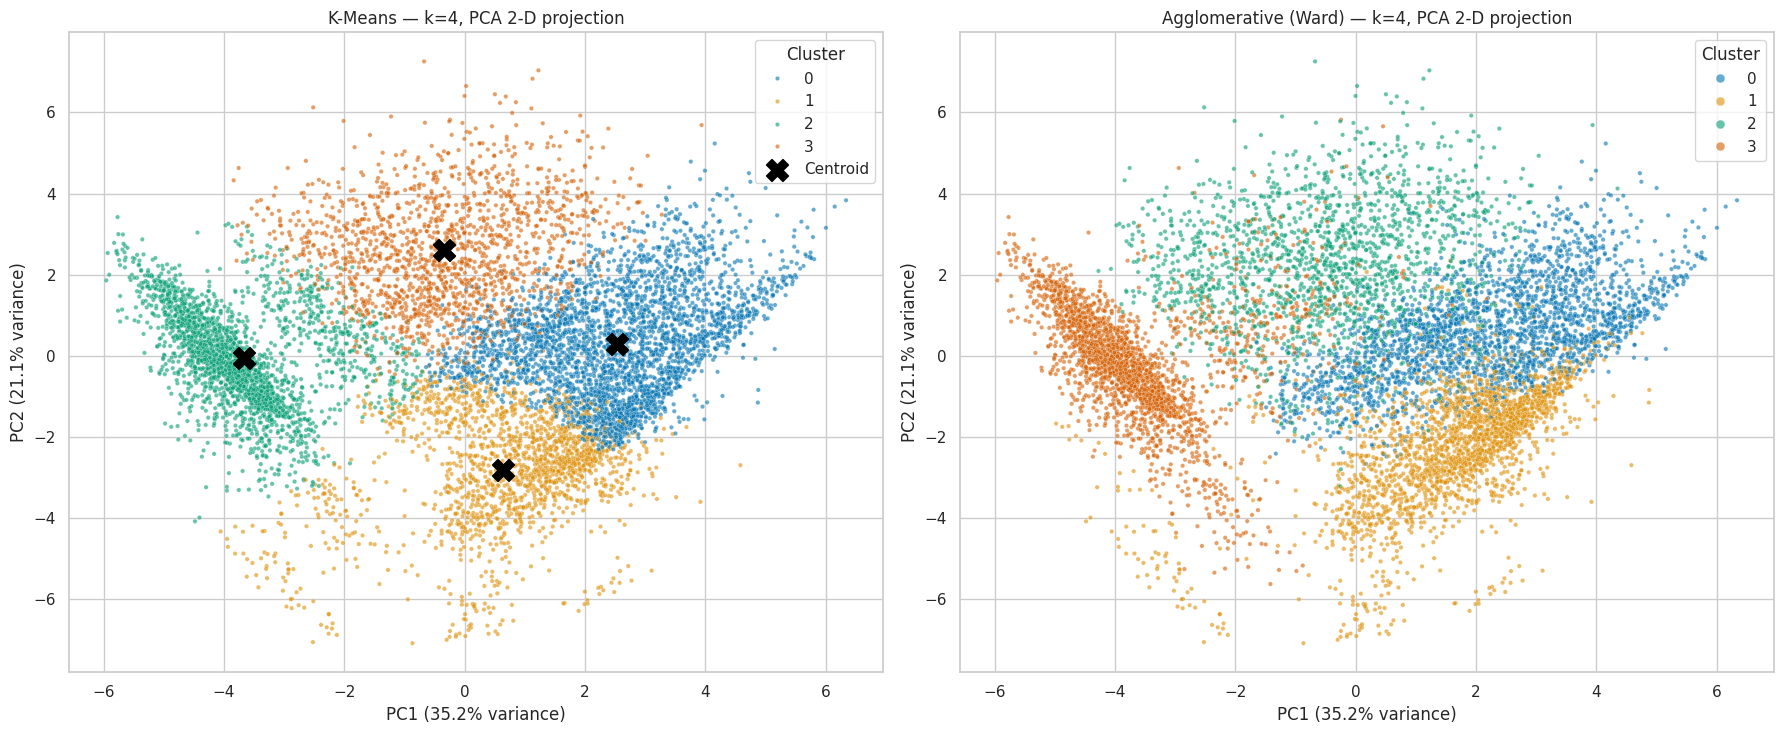

PC1 + PC2 explain 56.3% of the variance of the scaled features.


In [22]:
centroids_2d = pca_2d_vis.transform(pca.inverse_transform(kmeans.cluster_centers_))

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (name, lab) in zip(axes, [('K-Means', labels_km), ('Agglomerative (Ward)', labels_ag)]):
    sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=lab, palette='colorblind', s=10, alpha=0.6, ax=ax, legend='full')
    ax.set_title(f'{name} — k={FINAL_K}, PCA 2-D projection')
    ax.set_xlabel(f'PC1 ({pca_2d_vis.explained_variance_ratio_[0]:.1%} variance)')
    ax.set_ylabel(f'PC2 ({pca_2d_vis.explained_variance_ratio_[1]:.1%} variance)')
    ax.legend(title='Cluster', markerscale=2)
axes[0].scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=250, c='black', label='Centroid')
axes[0].legend(title='Cluster')
plt.tight_layout()
plt.savefig('../models/clu_pca_2d_clusters.png', bbox_inches='tight')
plt.show()

print(f'PC1 + PC2 explain {pca_2d_vis.explained_variance_ratio_.sum():.1%} of the variance of the scaled features.')

**Observation:** In the PCA plane (PC1 + PC2 = 56% of the variance), **PC1 separates cash-advance users (left) from purchasers (right)**. The cash-advance revolvers (K-Means cluster 2) form the tightest, most distinct group. The four K-Means clusters occupy clear regions with centroids well apart, but their edges touch, which matches the moderate silhouette. Ward finds the same overall structure but draws the boundary of its purchase-driven clusters differently (its cluster 2 spreads diagonally across the upper half).

### F2 — t-SNE visualisation

t-SNE is a non-linear projection that preserves *local* neighbourhoods, so it can show separation that the linear 2-D PCA view squashes. It is used only for visualisation (distances between far-apart t-SNE groups are not meaningful).

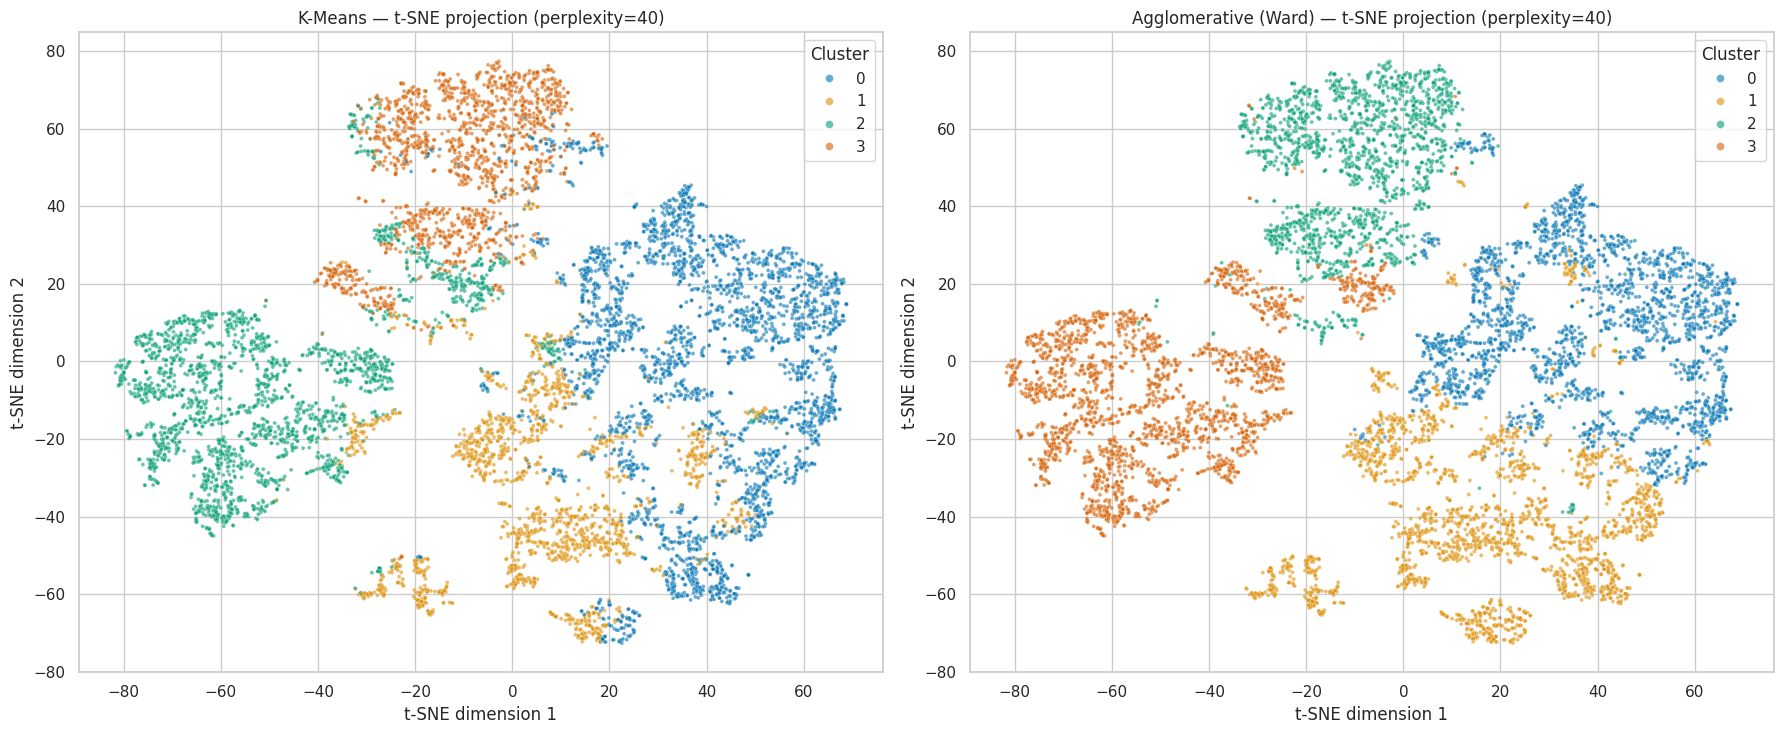

In [23]:
tsne = TSNE(n_components=2, perplexity=40, init='pca', learning_rate='auto', random_state=RANDOM_STATE)
X_tsne = tsne.fit_transform(X_pca)

fig, axes = plt.subplots(1, 2, figsize=(18, 7.5))
for ax, (name, lab) in zip(axes, [('K-Means', labels_km), ('Agglomerative (Ward)', labels_ag)]):
    sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=lab, palette='colorblind', s=8, alpha=0.6, ax=ax, legend='full')
    ax.set_title(f'{name} — t-SNE projection (perplexity=40)')
    ax.set_xlabel('t-SNE dimension 1')
    ax.set_ylabel('t-SNE dimension 2')
    ax.legend(title='Cluster', markerscale=2)
plt.tight_layout()
plt.savefig('../models/clu_tsne_clusters.png', bbox_inches='tight')
plt.show()

**Observation:** t-SNE, which preserves local neighbourhoods, shows the structure **much more clearly than PCA**. The cash-advance revolvers form a separate island on the left, and the active transactors form a large connected region on the right. Both algorithms colour these islands almost identically. The low-activity (yellow) customers form several small sub-islands, which is the part of the data where K-Means and Ward disagree most. A finer segmentation could split this group further, but it is the lowest-risk group, so splitting it adds little for a risk use case.

## Section G — Cluster Profiling & Risk Interpretation

Clusters are only useful if they mean something. Each K-Means cluster is described with the **medians** of the original (un-transformed) features — medians because the money columns are heavily skewed.

In [24]:
profile_cols = ['BALANCE', 'CREDIT_LIMIT', 'CREDIT_UTILIZATION', 'PURCHASES', 'ONEOFF_PURCHASES',
                'INSTALLMENTS_PURCHASES', 'PURCHASES_FREQUENCY', 'CASH_ADVANCE', 'CASH_ADVANCE_FREQUENCY',
                'PAYMENTS', 'PAYMENT_TO_MIN_RATIO', 'PRC_FULL_PAYMENT', 'TENURE']

df_profile = df_feat.copy()
df_profile['Cluster'] = labels_km
profile = df_profile.groupby('Cluster')[profile_cols].median()
profile['Customers'] = df_profile['Cluster'].value_counts().sort_index()
profile['Share'] = profile['Customers'] / profile['Customers'].sum()
profile.style.format('{:,.2f}').format({'Customers': '{:,.0f}', 'Share': '{:.1%}'}).background_gradient(cmap='YlOrRd', axis=0)

,BALANCE,CREDIT_LIMIT,CREDIT_UTILIZATION,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,PURCHASES_FREQUENCY,CASH_ADVANCE,CASH_ADVANCE_FREQUENCY,PAYMENTS,PAYMENT_TO_MIN_RATIO,PRC_FULL_PAYMENT,TENURE,Customers,Share
Cluster,,,,,,,,,,,,,,,
0,464.889030,4000.000000,0.130597,1052.620000,401.210000,457.200000,0.916667,0.000000,0.000000,1105.254047,3.723414,0.083333,12.000000,"3,204",35.8%
1,28.800710,2500.000000,0.011152,177.210000,0.000000,51.700000,0.250000,0.000000,0.000000,276.870232,2.199146,0.000000,12.000000,"1,773",19.8%
2,1568.889279,3000.000000,0.671430,0.000000,0.000000,0.000000,0.000000,1194.998121,0.250000,771.904587,1.088586,0.000000,12.000000,"2,374",26.5%
3,2283.090556,4500.000000,0.599885,818.355000,418.700000,274.005000,0.750000,1471.525984,0.250000,1578.787584,1.416793,0.000000,12.000000,"1,598",17.9%


### G1 — Naming the segments

The names are assigned **by rules on the profile**, not by hand-picking cluster numbers, so they stay correct even if the (arbitrary) cluster numbering changed:

- **Dormant / low-activity** — the cluster with the lowest combined balance, purchases and cash advance.
- **Cash-advance revolvers** — of the rest, the cluster that uses cash advances most and purchases least.
- **Active transactors** — of the rest, the cluster that repays the most relative to the minimum payment.
- **Heavy revolving spenders** — the remaining cluster.

The risk level follows from utilisation and repayment behaviour (high utilisation + paying only ~the minimum = high risk).

In [25]:
remaining = list(profile.index)

dormant = profile.loc[remaining, ['BALANCE', 'PURCHASES', 'CASH_ADVANCE']].sum(axis=1).idxmin(); remaining.remove(dormant)
cash = (profile.loc[remaining, 'CASH_ADVANCE_FREQUENCY'] - profile.loc[remaining, 'PURCHASES_FREQUENCY']).idxmax(); remaining.remove(cash)
transactor = profile.loc[remaining, 'PAYMENT_TO_MIN_RATIO'].idxmax(); remaining.remove(transactor)
heavy = remaining[0]

SEGMENTS = {
    transactor: {'name': 'Active Transactors', 'risk': 'Low',
                 'summary': 'Frequent card purchases, low utilisation, repay well above the minimum.',
                 'action': 'Retain & reward: cashback / credit-limit increase offers.'},
    dormant: {'name': 'Dormant / Low-Activity', 'risk': 'Low',
              'summary': 'Very low balances and little card usage of any kind.',
              'action': 'Re-activation campaigns; low credit risk but low revenue.'},
    heavy: {'name': 'Heavy Revolving Spenders', 'risk': 'Medium-High',
            'summary': 'High balances from both purchases and cash advances, high utilisation, pay only a little above the minimum.',
            'action': 'Monitor utilisation; offer balance-transfer / instalment conversion.'},
    cash: {'name': 'Cash-Advance Revolvers', 'risk': 'High',
           'summary': 'Almost no purchases, rely on cash advances, high utilisation, pay close to the minimum.',
           'action': 'Highest risk: tighten cash-advance limits, early-warning collections.'},
}

segment_table = pd.DataFrame([{'Cluster': c, 'Segment': s['name'], 'Risk level': s['risk'],
                               'Customers': int(profile.loc[c, 'Customers']), 'Share': profile.loc[c, 'Share'],
                               'Median utilisation': profile.loc[c, 'CREDIT_UTILIZATION'],
                               'Median payment/min ratio': profile.loc[c, 'PAYMENT_TO_MIN_RATIO'],
                               'Profile': s['summary']} for c, s in sorted(SEGMENTS.items())])
segment_table.style.format({'Share': '{:.1%}', 'Median utilisation': '{:.2f}', 'Median payment/min ratio': '{:.2f}'}).hide(axis='index')

Cluster,Segment,Risk level,Customers,Share,Median utilisation,Median payment/min ratio,Profile
0,Active Transactors,Low,3204,35.8%,0.13,3.72,"Frequent card purchases, low utilisation, repay well above the minimum."
1,Dormant / Low-Activity,Low,1773,19.8%,0.01,2.20,Very low balances and little card usage of any kind.
2,Cash-Advance Revolvers,High,2374,26.5%,0.67,1.09,"Almost no purchases, rely on cash advances, high utilisation, pay close to the minimum."
3,Heavy Revolving Spenders,Medium-High,1598,17.9%,0.60,1.42,"High balances from both purchases and cash advances, high utilisation, pay only a little above the minimum."


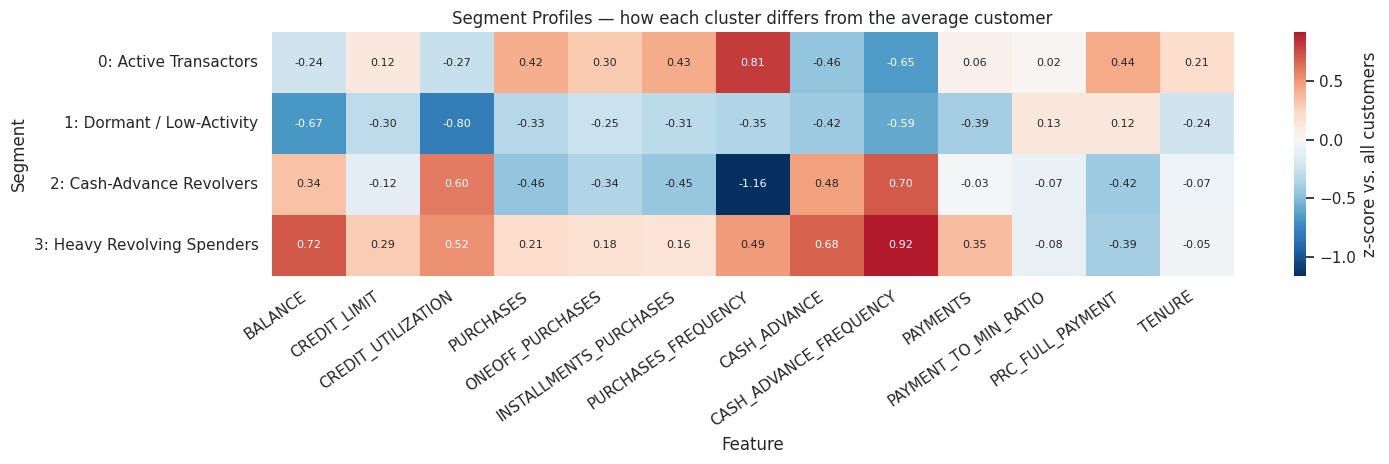

In [26]:
# Standardised (z-score) profile of every cluster centre -> which behaviours make each segment different.
z_profile = df_profile.groupby('Cluster')[profile_cols].mean()
z_profile = (z_profile - df_profile[profile_cols].mean()) / df_profile[profile_cols].std()
z_profile.index = [f"{c}: {SEGMENTS[c]['name']}" for c in z_profile.index]

plt.figure(figsize=(15, 4.8))
sns.heatmap(z_profile, cmap='RdBu_r', center=0, annot=True, fmt='.2f', annot_kws={'size': 8},
            cbar_kws={'label': 'z-score vs. all customers'})
plt.title('Segment Profiles — how each cluster differs from the average customer')
plt.xlabel('Feature'); plt.ylabel('Segment')
plt.xticks(rotation=35, ha='right')
plt.tight_layout()
plt.savefig('../models/clu_segment_profile_heatmap.png', bbox_inches='tight')
plt.show()

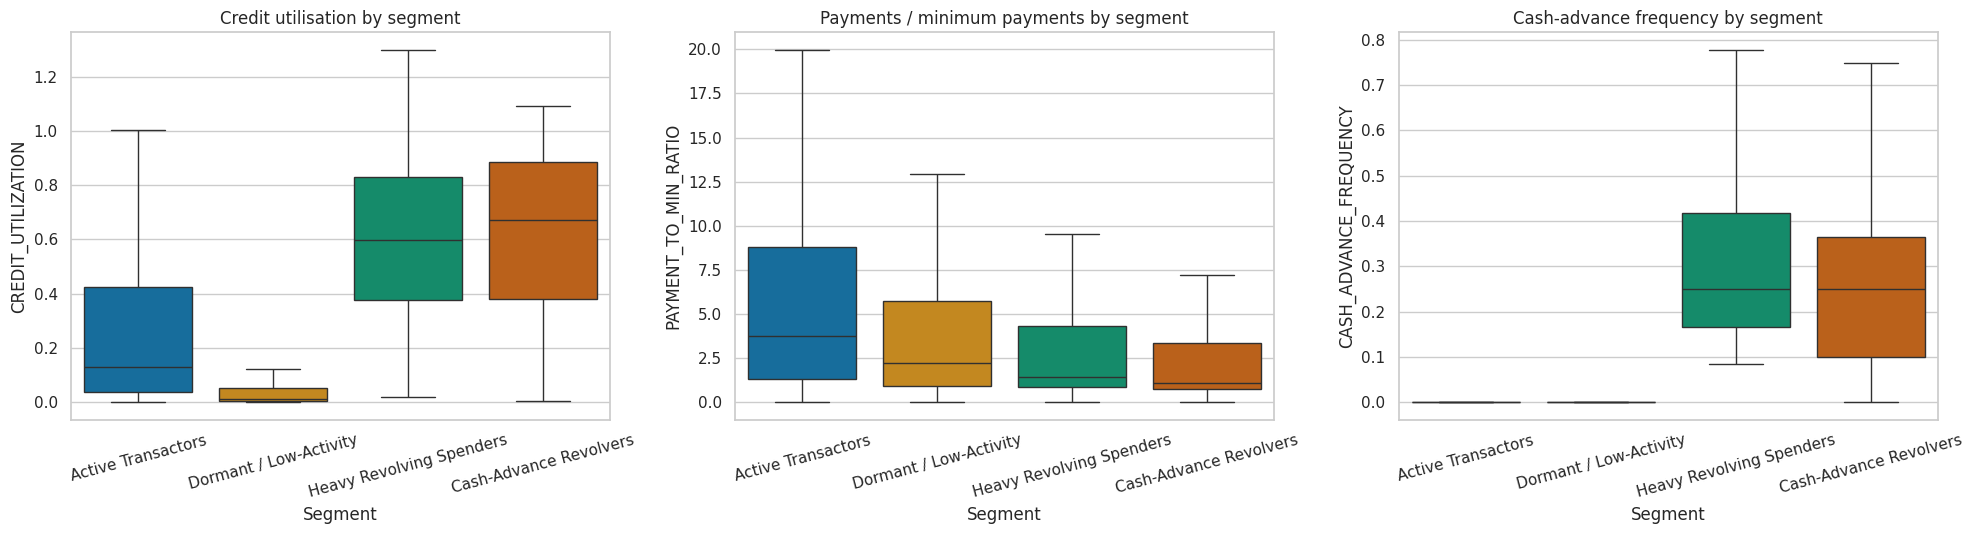

In [27]:
seg_names = pd.Series(labels_km).map(lambda c: SEGMENTS[c]['name'])
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
order = [SEGMENTS[c]['name'] for c in [transactor, dormant, heavy, cash]]
for ax, col, title in zip(axes, ['CREDIT_UTILIZATION', 'PAYMENT_TO_MIN_RATIO', 'CASH_ADVANCE_FREQUENCY'],
                          ['Credit utilisation', 'Payments / minimum payments', 'Cash-advance frequency']):
    sns.boxplot(x=seg_names.values, y=df_feat[col].values, order=order, ax=ax, palette='colorblind', showfliers=False)
    ax.set_title(f'{title} by segment')
    ax.set_xlabel('Segment'); ax.set_ylabel(col)
    ax.tick_params(axis='x', rotation=15)
plt.tight_layout()
plt.savefig('../models/clu_segment_risk_boxplots.png', bbox_inches='tight')
plt.show()

**Observation — what the segments mean for credit risk:**

| Segment | Share | What defines it | Risk |
|---|---|---|---|
| **Active Transactors** | 35.8% | highest purchase frequency (z = +0.81), lowest cash-advance use, median utilisation only 13%, repay **3.7x** the minimum | **Low**: profitable, low-risk core customers |
| **Dormant / Low-Activity** | 19.8% | lowest balance and utilisation (1%) and little activity of any kind | **Low** credit risk but low value; target for re-activation |
| **Cash-Advance Revolvers** | 26.5% | almost **no purchases** (z = −1.16 on purchase frequency), heavy cash advances, utilisation **67%**, repay only **1.09x** the minimum, rarely pay in full | **High**: borrowing cash on the card and revolving it |
| **Heavy Revolving Spenders** | 17.9% | highest balances (z = +0.72) and the most frequent cash advances (z = +0.92) **plus** regular purchases, utilisation 60%, repay 1.42x the minimum | **Medium-High**: large exposure; fine while income holds, vulnerable if it drops |

The box plots confirm that the segments separate cleanly on exactly the engineered risk features: utilisation and the payment-to-minimum ratio split the two low-risk segments from the two revolving segments. Together, the two high-risk revolving segments are **44% of the portfolio**, which is where a lender would focus monitoring and collections.

### G2 — Stability check

Without labels, one way to validate clusters is to check that they are **reproducible**: K-Means is re-run with 10 different random seeds and each result is compared with the final model using the Adjusted Rand Index (ARI).

In [28]:
stability = [adjusted_rand_score(labels_km, KMeans(n_clusters=FINAL_K, n_init=10, random_state=seed).fit_predict(X_pca))
             for seed in range(10)]
print(f'K-Means stability across 10 seeds: mean ARI = {np.mean(stability):.3f} (min {np.min(stability):.3f}, max {np.max(stability):.3f})')

K-Means stability across 10 seeds: mean ARI = 0.987 (min 0.979, max 0.998)


**Observation:** Re-running K-Means with 10 different seeds gives almost exactly the same segmentation (mean **ARI = 0.987**, minimum 0.979). The segments are therefore a stable property of the data, not an artefact of one lucky initialisation. Together with the K-Means/Ward agreement (ARI 0.55) and the clear business profiles, this is the strongest validation available for an unlabelled dataset.

## Conclusion (Clustering track)

- **Data:** 8,950 real credit-card customers. Missing `MINIMUM_PAYMENTS` were treated as **structurally missing** (240 set to 0, 73 median-filled), 1 row without a credit limit was dropped, and 8 invalid frequencies were clipped. Outliers were kept and handled with `log1p`. Four ratio/per-month risk features were engineered, and PCA reduced 21 features to 8 components (91.3% of the variance).
- **K-Means (k = 4)**, chosen with the elbow curve, a flat silhouette profile and the dendrogram's natural cut: **Silhouette 0.242, Davies-Bouldin 1.515, Calinski-Harabasz 2,803**. It is very stable across seeds (ARI 0.987).
- **Agglomerative (Ward, k = 4):** Silhouette 0.200, DB 1.715, CH 2,371. Single, average and complete linkage produce degenerate clusters, even though single linkage has the best Silhouette/DB scores. That is a reminder that metrics must be read together with cluster sizes.
- **Final model: K-Means.** It is better on all three metrics and stable, and unlike Agglomerative clustering it can **assign new customers** with `predict()`, which the web app needs.
- **Outcome:** four interpretable segments. Two of them (**Cash-Advance Revolvers** and **Heavy Revolving Spenders**, 44% of customers) combine high utilisation with near-minimum repayments and are the high-risk part of the portfolio. This connects back to the project's theme: the same risk signals (utilisation, debt burden, repayment behaviour) that drive the loan **RiskScore** in the regression track separate the risky segments here.

## Save the clustering model

Agglomerative clustering has no `predict()` for new customers (it only labels the points it was fitted on), so **K-Means** is the deployable model. Every fitted object needed to assign a *new* customer to a segment — the imputation value, the log-transformed columns, the scaler, PCA and K-Means — is saved in one bundle, which the web app (`app/`) loads.

In [29]:
import joblib
import json

bundle = {
    'feature_order': FEATURE_ORDER,
    'skewed_cols': skewed_cols,
    'min_payments_median': float(MIN_PAYMENTS_MEDIAN),
    'scaler': scaler,
    'pca': pca,
    'kmeans': kmeans,
    'pca_2d': pca_2d_vis,
    'segments': {int(k): v for k, v in SEGMENTS.items()},
}
joblib.dump(bundle, '../models/clu_kmeans_bundle.pkl')
joblib.dump(agglo, '../models/clu_agglomerative_ward.pkl')
print('Saved ../models/clu_kmeans_bundle.pkl and ../models/clu_agglomerative_ward.pkl')

metrics_df.to_csv('../models/clu_metrics.csv', index=False)
k_df.to_csv('../models/clu_k_selection.csv', index=False)
segment_table.to_csv('../models/clu_segments.csv', index=False)

# A small random sample of PCA-2D points (with K-Means labels) for the web app's scatter chart.
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(X_2d), size=1500, replace=False)
sample_points = [{'x': round(float(X_2d[i, 0]), 3), 'y': round(float(X_2d[i, 1]), 3), 'c': int(labels_km[i])} for i in idx]
with open('../models/clu_pca_sample.json', 'w') as f:
    json.dump(sample_points, f)
print('Saved metrics, k-selection, segment tables and a 1,500-point PCA sample for the web app.')

Saved ../models/clu_kmeans_bundle.pkl and ../models/clu_agglomerative_ward.pkl
Saved metrics, k-selection, segment tables and a 1,500-point PCA sample for the web app.


### Demo: assign a new customer to a segment

In [30]:
def assign_segment(customer: dict, b=bundle):
    """Apply the exact notebook preprocessing to one raw customer record and return its segment."""
    row = pd.DataFrame([customer])
    if pd.isna(row.loc[0, 'MINIMUM_PAYMENTS']):
        row.loc[0, 'MINIMUM_PAYMENTS'] = 0.0 if row.loc[0, 'PAYMENTS'] == 0 else b['min_payments_median']
    row['CASH_ADVANCE_FREQUENCY'] = row['CASH_ADVANCE_FREQUENCY'].clip(upper=1.0)
    row = engineer_features(row)
    row[b['skewed_cols']] = np.log1p(row[b['skewed_cols']])
    z = b['pca'].transform(b['scaler'].transform(row[b['feature_order']]))
    cluster = int(b['kmeans'].predict(z)[0])
    return cluster, b['segments'][cluster]


loaded = joblib.load('../models/clu_kmeans_bundle.pkl')
customer = df.drop(columns=['ID']).iloc[1].to_dict()
cluster, seg = assign_segment(customer, loaded)
print('Customer:', {k: round(v, 2) for k, v in customer.items()})
print(f"\n-> Cluster {cluster}: {seg['name']} (risk: {seg['risk']})")
print(f"   {seg['summary']}")

# Sanity check: the saved bundle reproduces the notebook's labels for every customer.
check = [assign_segment(r, loaded)[0] for r in df_clean.head(500).to_dict('records')]
print(f'\nBundle reproduces notebook labels on 500 customers: {np.mean(np.array(check) == labels_km[:500]):.1%}')

Customer: {'BALANCE': 3202.47, 'BALANCE_FREQUENCY': 0.91, 'PURCHASES': 0.0, 'ONEOFF_PURCHASES': 0.0, 'INSTALLMENTS_PURCHASES': 0.0, 'CASH_ADVANCE': 6442.95, 'PURCHASES_FREQUENCY': 0.0, 'ONEOFF_PURCHASES_FREQUENCY': 0.0, 'PURCHASES_INSTALLMENTS_FREQUENCY': 0.0, 'CASH_ADVANCE_FREQUENCY': 0.25, 'CASH_ADVANCE_TRX': 4.0, 'PURCHASES_TRX': 0.0, 'CREDIT_LIMIT': 7000.0, 'PAYMENTS': 4103.03, 'MINIMUM_PAYMENTS': 1072.34, 'PRC_FULL_PAYMENT': 0.22, 'TENURE': 12.0}

-> Cluster 2: Cash-Advance Revolvers (risk: High)
   Almost no purchases, rely on cash advances, high utilisation, pay close to the minimum.



Bundle reproduces notebook labels on 500 customers: 100.0%


## Pick a clustering algorithm to run live

Set `ALGORITHM` to `'K-Means'` or `'Agglomerative (Ward)'` and re-run this cell to assign the same new customer under either fitted model. K-Means has a native `predict()` for new points; Agglomerative does not (scikit-learn only exposes the labels it assigned while fitting), so a new customer is matched to its nearest already-labelled training point in the same PCA space, and the segment name shown is the K-Means segment that Ward cluster overlaps with most (the same majority-overlap idea as the K-Means-vs-Ward crosstab above).

In [31]:
from sklearn.neighbors import NearestNeighbors

ALGORITHM = 'Agglomerative (Ward)'   # <- 'K-Means' or 'Agglomerative (Ward)'

ward_centroids = np.array([X_pca[labels_ag == c].mean(axis=0) for c in np.unique(labels_ag)])
nn_index = NearestNeighbors(n_neighbors=1).fit(X_pca)
overlap = pd.crosstab(pd.Series(labels_ag), pd.Series(labels_km))
ward_to_kmeans_segment = overlap.idxmax(axis=1).to_dict()

customer = df.drop(columns=['ID']).iloc[1].to_dict()
row = pd.DataFrame([customer])
if pd.isna(row.loc[0, 'MINIMUM_PAYMENTS']):
    row.loc[0, 'MINIMUM_PAYMENTS'] = 0.0 if row.loc[0, 'PAYMENTS'] == 0 else MIN_PAYMENTS_MEDIAN
row['CASH_ADVANCE_FREQUENCY'] = row['CASH_ADVANCE_FREQUENCY'].clip(upper=1.0)
row = engineer_features(row)
row[skewed_cols] = np.log1p(row[skewed_cols])
z = pca.transform(scaler.transform(row[FEATURE_ORDER]))

if ALGORITHM == 'K-Means':
    cluster = int(kmeans.predict(z)[0])
    seg = SEGMENTS[cluster]
    note = 'Direct K-Means predict() on the new point.'
elif ALGORITHM == 'Agglomerative (Ward)':
    nn_row = nn_index.kneighbors(z, return_distance=False)[0, 0]
    ward_cluster = int(labels_ag[nn_row])
    seg_cluster = ward_to_kmeans_segment[ward_cluster]
    seg = SEGMENTS[seg_cluster]
    cluster = ward_cluster
    note = (f'Nearest-neighbour match to Ward cluster {ward_cluster} (no native predict()); '
            f'segment reused from its majority-overlap K-Means segment {seg_cluster}.')
else:
    raise ValueError("ALGORITHM must be 'K-Means' or 'Agglomerative (Ward)'")

print(f'Algorithm used: {ALGORITHM}')
print(note)
print(f"\n-> Cluster {cluster}: {seg['name']} (risk: {seg['risk']})")
print(f"   {seg['summary']}")

Algorithm used: Agglomerative (Ward)
Nearest-neighbour match to Ward cluster 3 (no native predict()); segment reused from its majority-overlap K-Means segment 2.

-> Cluster 3: Cash-Advance Revolvers (risk: High)
   Almost no purchases, rely on cash advances, high utilisation, pay close to the minimum.
